TASK 1 - Traveling Salesman Problem

In [ ]:
import math
import random

import numpy as np
import networkx as nx
import matplotlib.pyplot as plt

Function to generate graph

In [ ]:
def generate_vertex(n, val):
    G = [(i,i) for i in range (n)]
    if val == 0:
        G=[(random.random(),random.random()) for i in range (n)]
    elif val == 1:
        n = int(math.sqrt(n))
        G=[(i,j) for i in range (n) for j in range (n)]
        random.shuffle(G)
    elif val == 2:
        G = [(math.cos(2*math.pi*i/n),math.sin(2*math.pi*i/n)) for i in range (n)]
        random.shuffle(G)
    elif val == 3:
        centers = [(25, 25), (25, 75), (75, 25), (75, 75)]
        points = []
        for _ in range(n):
            points.append(np.random.normal(loc=random.choice(centers), scale=5, size=(1, 2))[0])
        G = np.array(points)
    elif val == 4:
        clusters = [(10, 10), (90, 90), (10, 90), (90, 10), (50, 50), (25, 75), (75, 25), (25, 25), (75, 75)]
        points = []
        for _ in range(n):
            points.append(np.random.normal(loc=random.choice(clusters), scale=2, size=(1, 2))[0])
        return np.array(points)
    elif val == 5:
        G = [(random.random()+i%3,random.random()+i//3) for _ in range (n//9) for i in range (9)]
    return np.array(G)

Temperature functions, cause
some problems may find a better use of logarithmic functions, exponential or linear

In [ ]:
def temp_log(temperature, parameter, iteration):
    # np.e gwarantuje płynny start od temperatury początkowej w iteracji 0
    return temperature / np.log(np.e + parameter * iteration)

def temp_exp(temperature, parameter, iteration):
    return temperature * (parameter ** iteration)

def temp_lin(temperature, parameter, iteration):
    # Zabezpieczenie przed temperaturą ujemną
    return max(0.0001, temperature - (parameter * iteration))

We will be using 2 different types of swapping to see which one is better

In [ ]:
#SWAPS
def swap_consecutive(G):
    G_new = G.copy()
    i = random.randint(0, len(G)-1)
    j = (i+1) % len(G)
    # Poprawna zamiana wierszy w NumPy
    G_new[[i, j]] = G_new[[j, i]]
    return G_new

def swap_arbitrary(G):
    G_new = G.copy()
    i, j = random.sample(range(len(G_new)), 2)
    # Poprawna zamiana wierszy w NumPy
    G_new[[i, j]] = G_new[[j, i]]
    return G_new

Simulated Annaelling Function

In [ ]:
def distance(a,b):
    return np.sqrt((a[0]-b[0])**2 + (a[1]-b[1])**2)

def energy(G):
    return sum(distance(p1,p2) for p1,p2 in zip(G,G[1:]))

def solve(Graph, Temp_func, Mod_func, max_iter, cooling_param):

    temperatures = []
    energies = []

    old_energy = energy(Graph)
    best_energy = old_energy
    best_graph = Graph.copy()

    for iteration in range(max_iter):
        temp = Temp_func(1.0, cooling_param,iteration)

        temperatures.append(temp)
        energies.append(old_energy)

        new_graph = Mod_func(Graph)
        new_energy = energy(new_graph)

        if new_energy < old_energy or random.random() < np.exp((old_energy-new_energy)/max(temp,1e-10)):
            Graph = new_graph
            old_energy = new_energy
            if new_energy<best_energy:
                best_graph = new_graph.copy()
                best_energy = new_energy

    Graph = best_graph
    temperatures.append(0)
    energies.append(best_energy)

    return Graph, temperatures, energies

Now it's time for visualisation

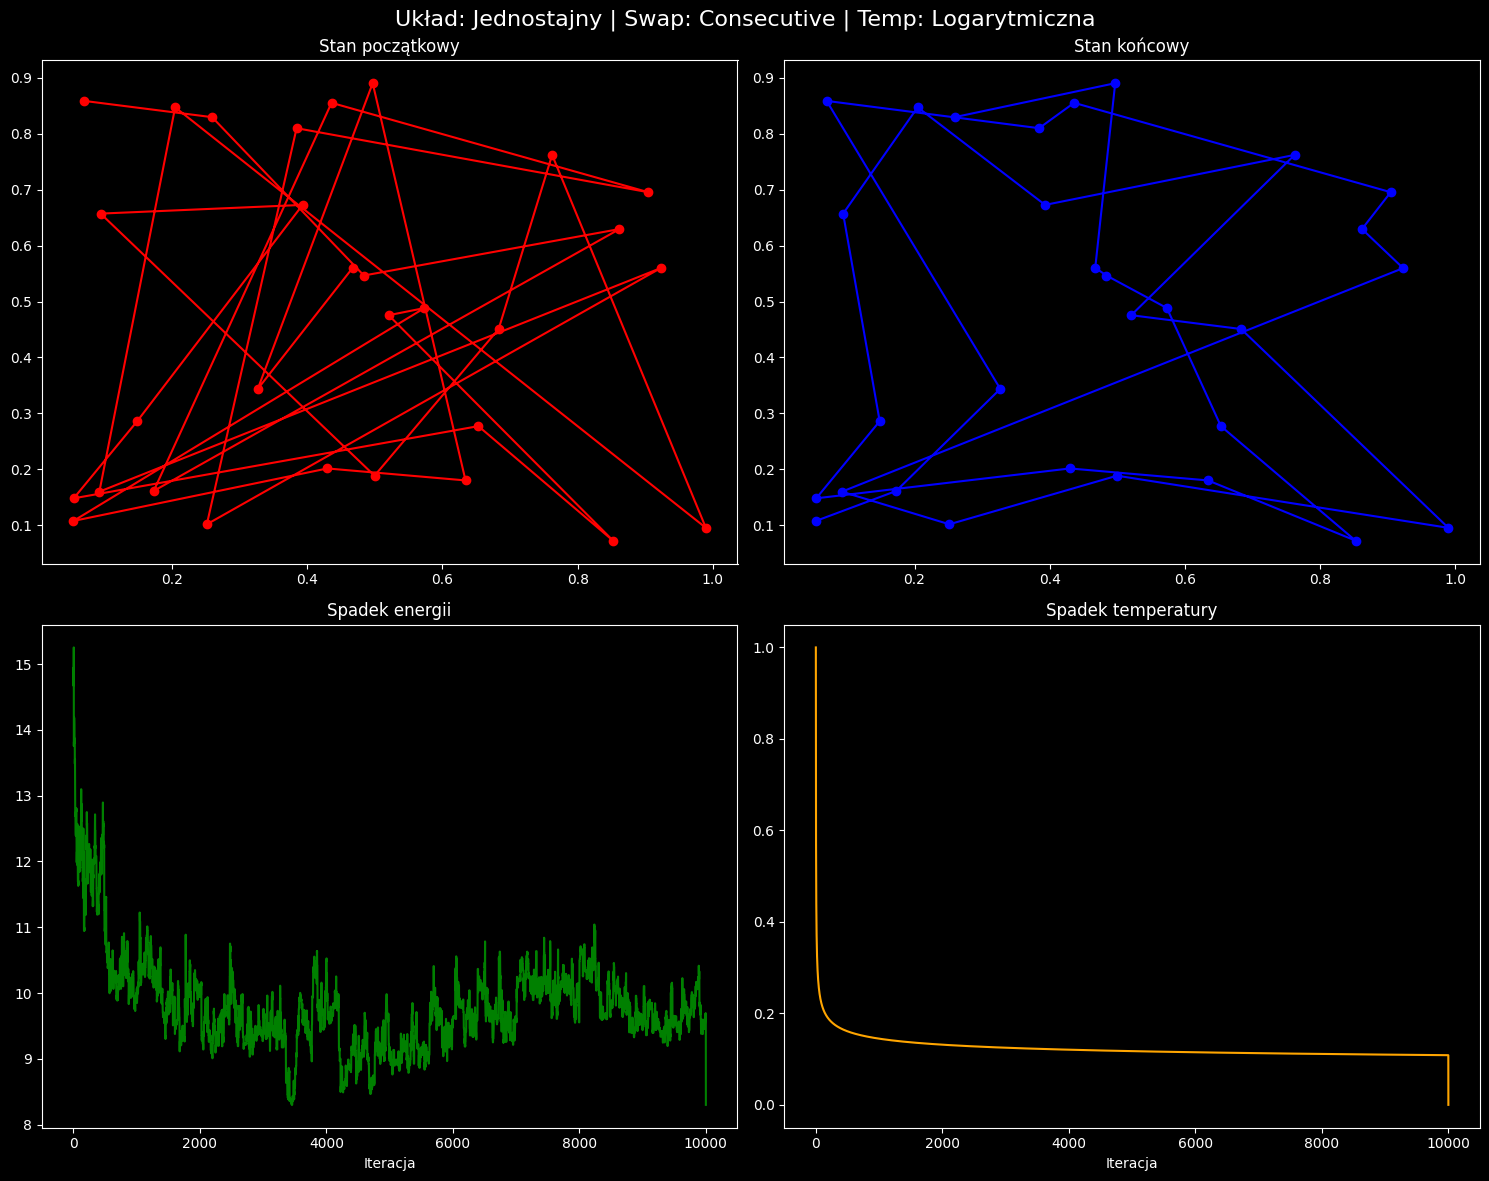

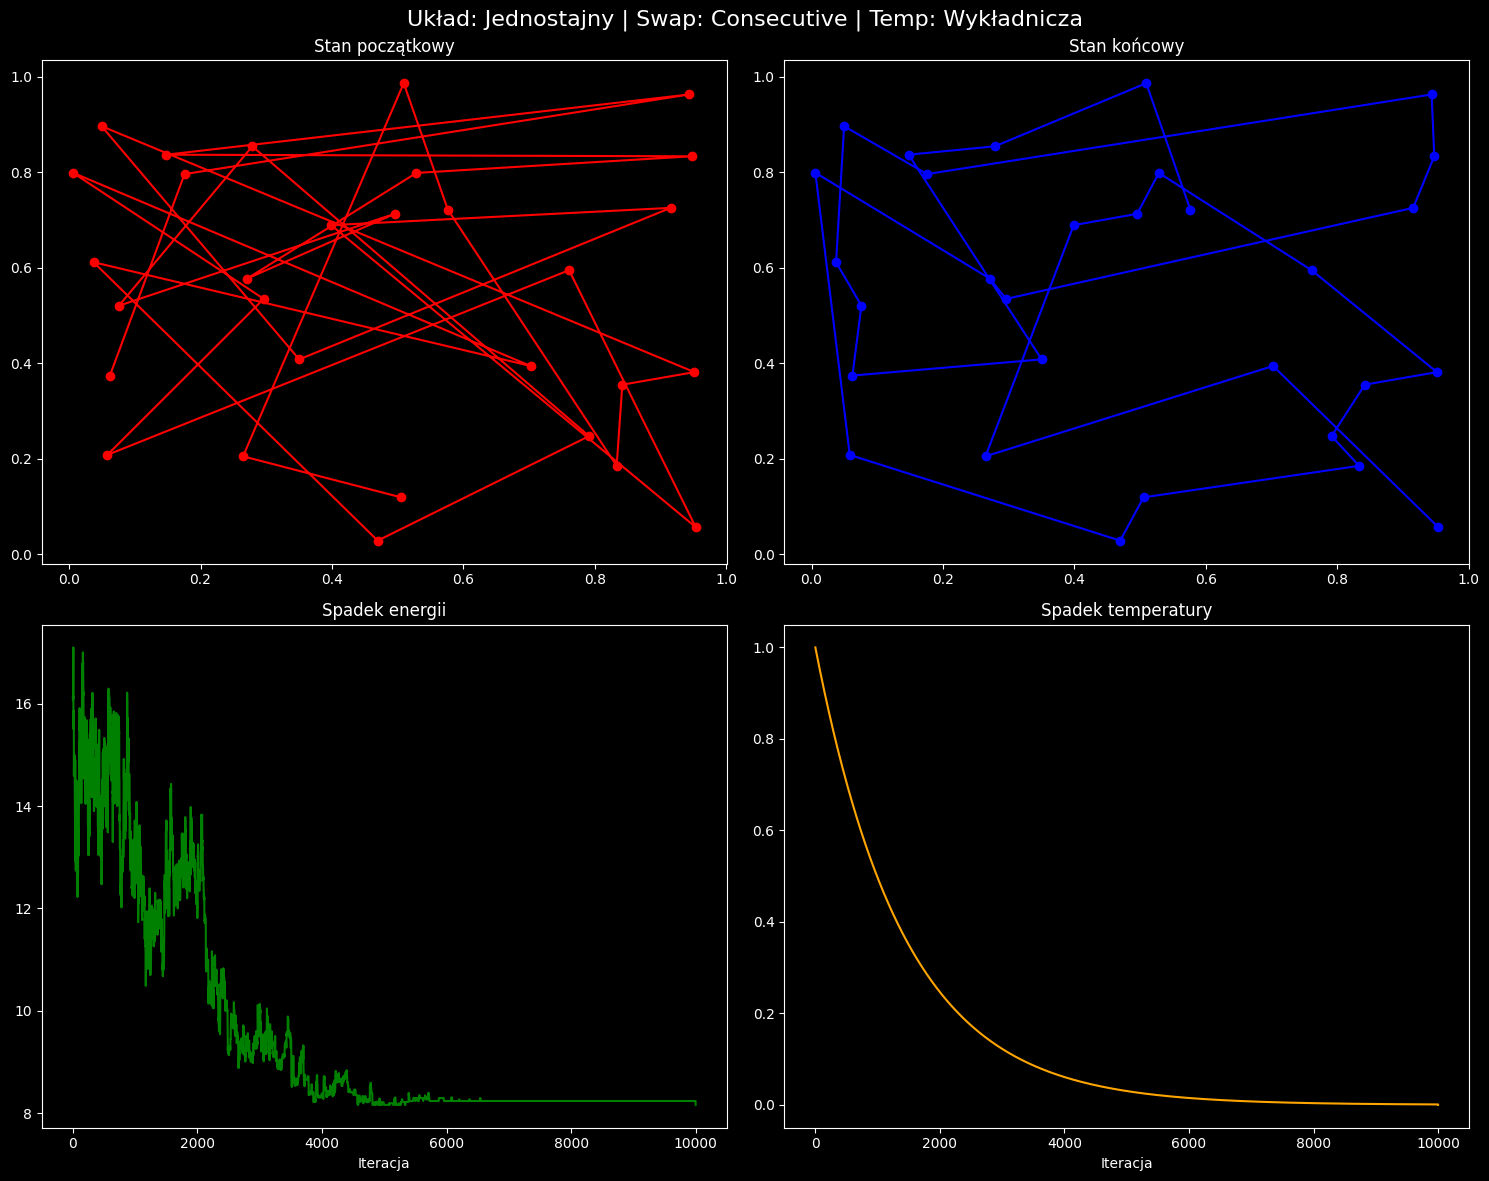

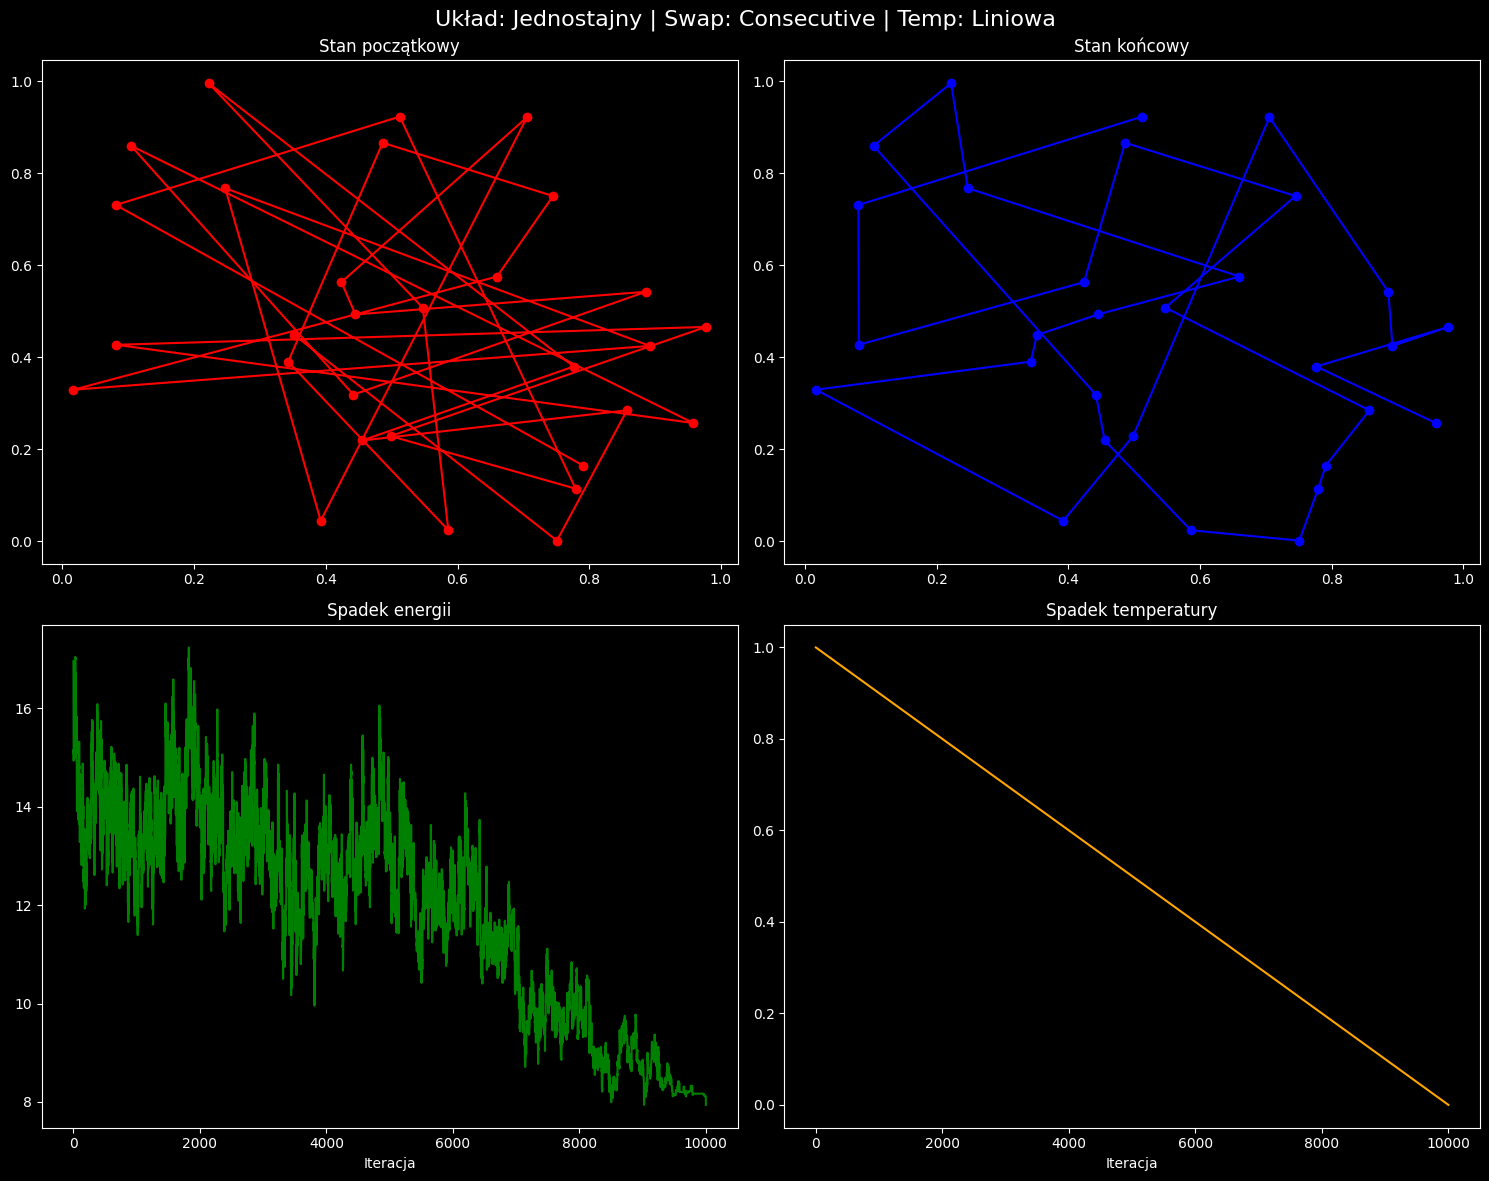

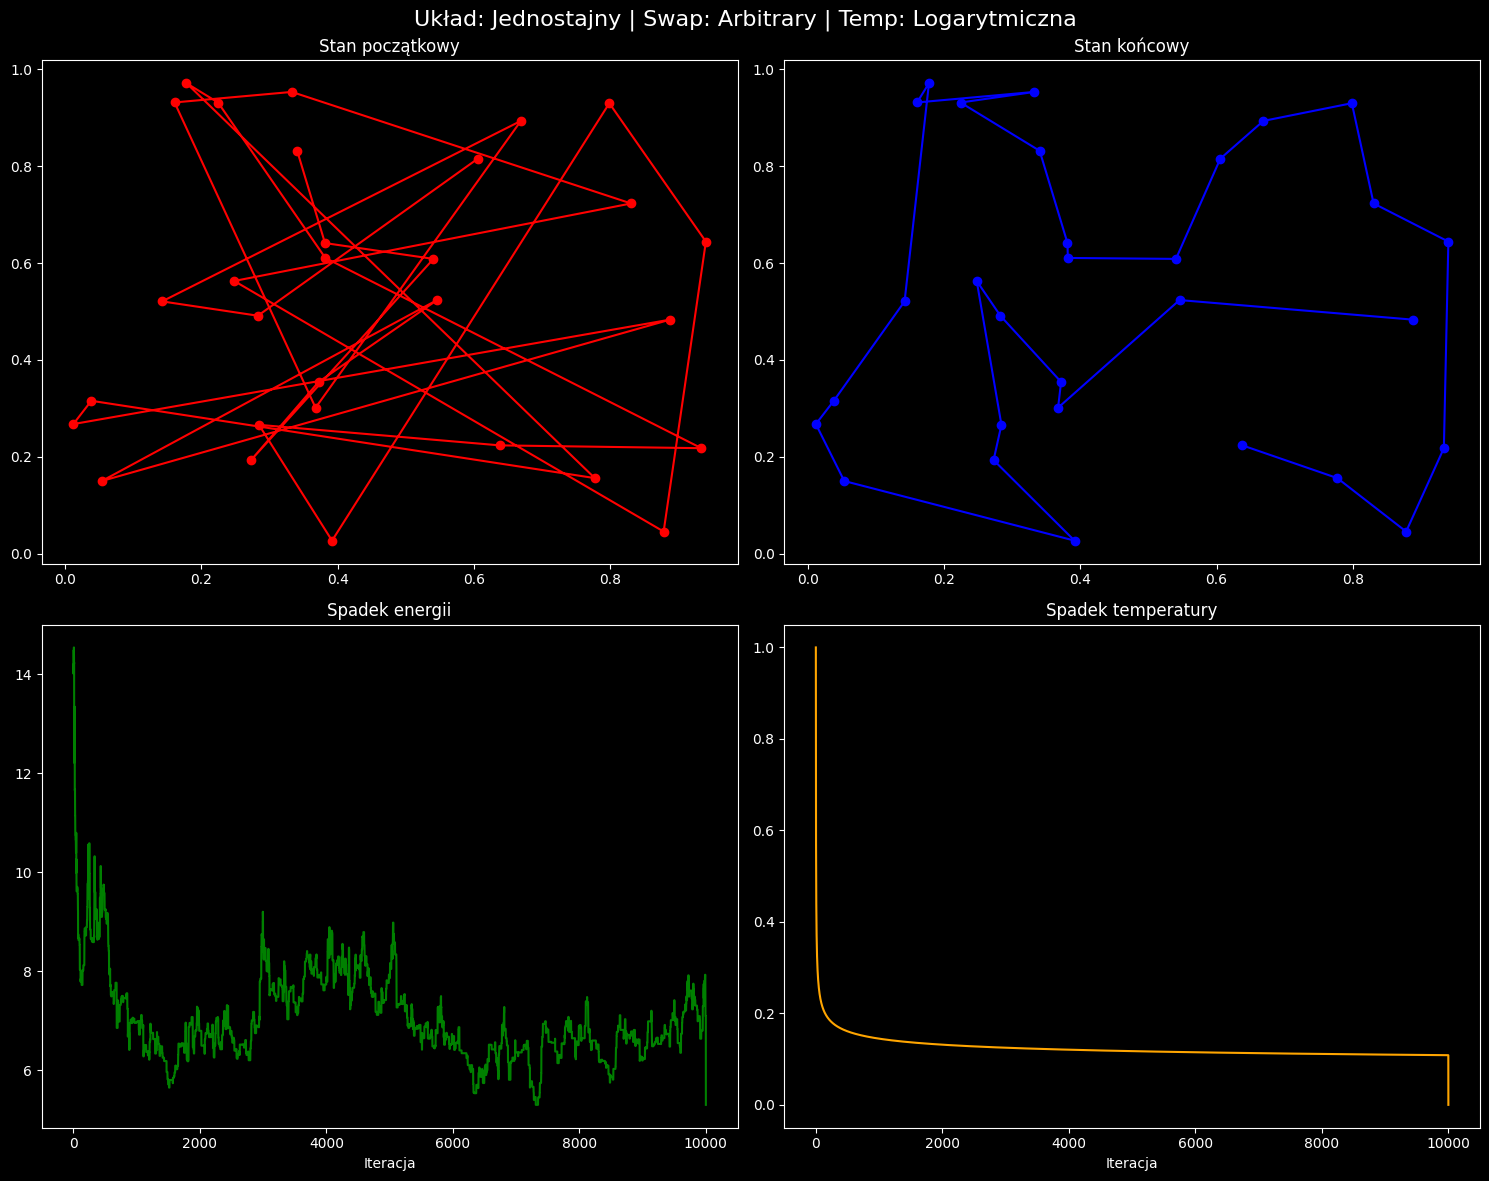

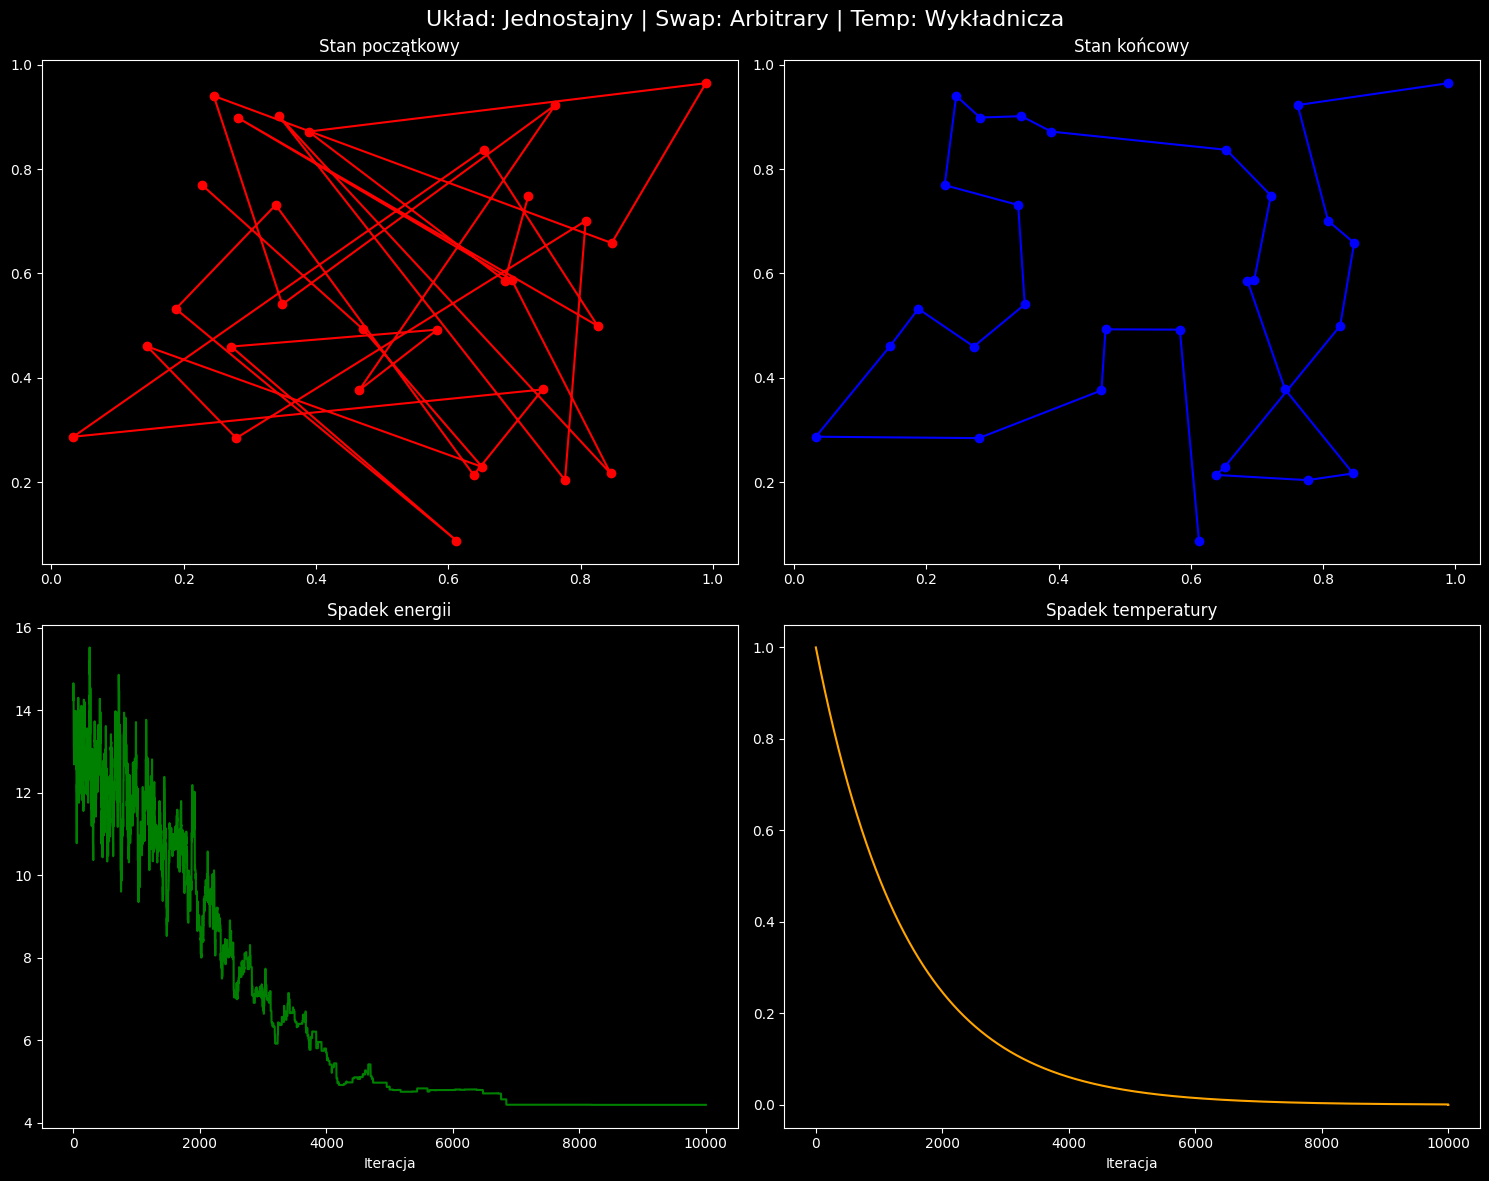

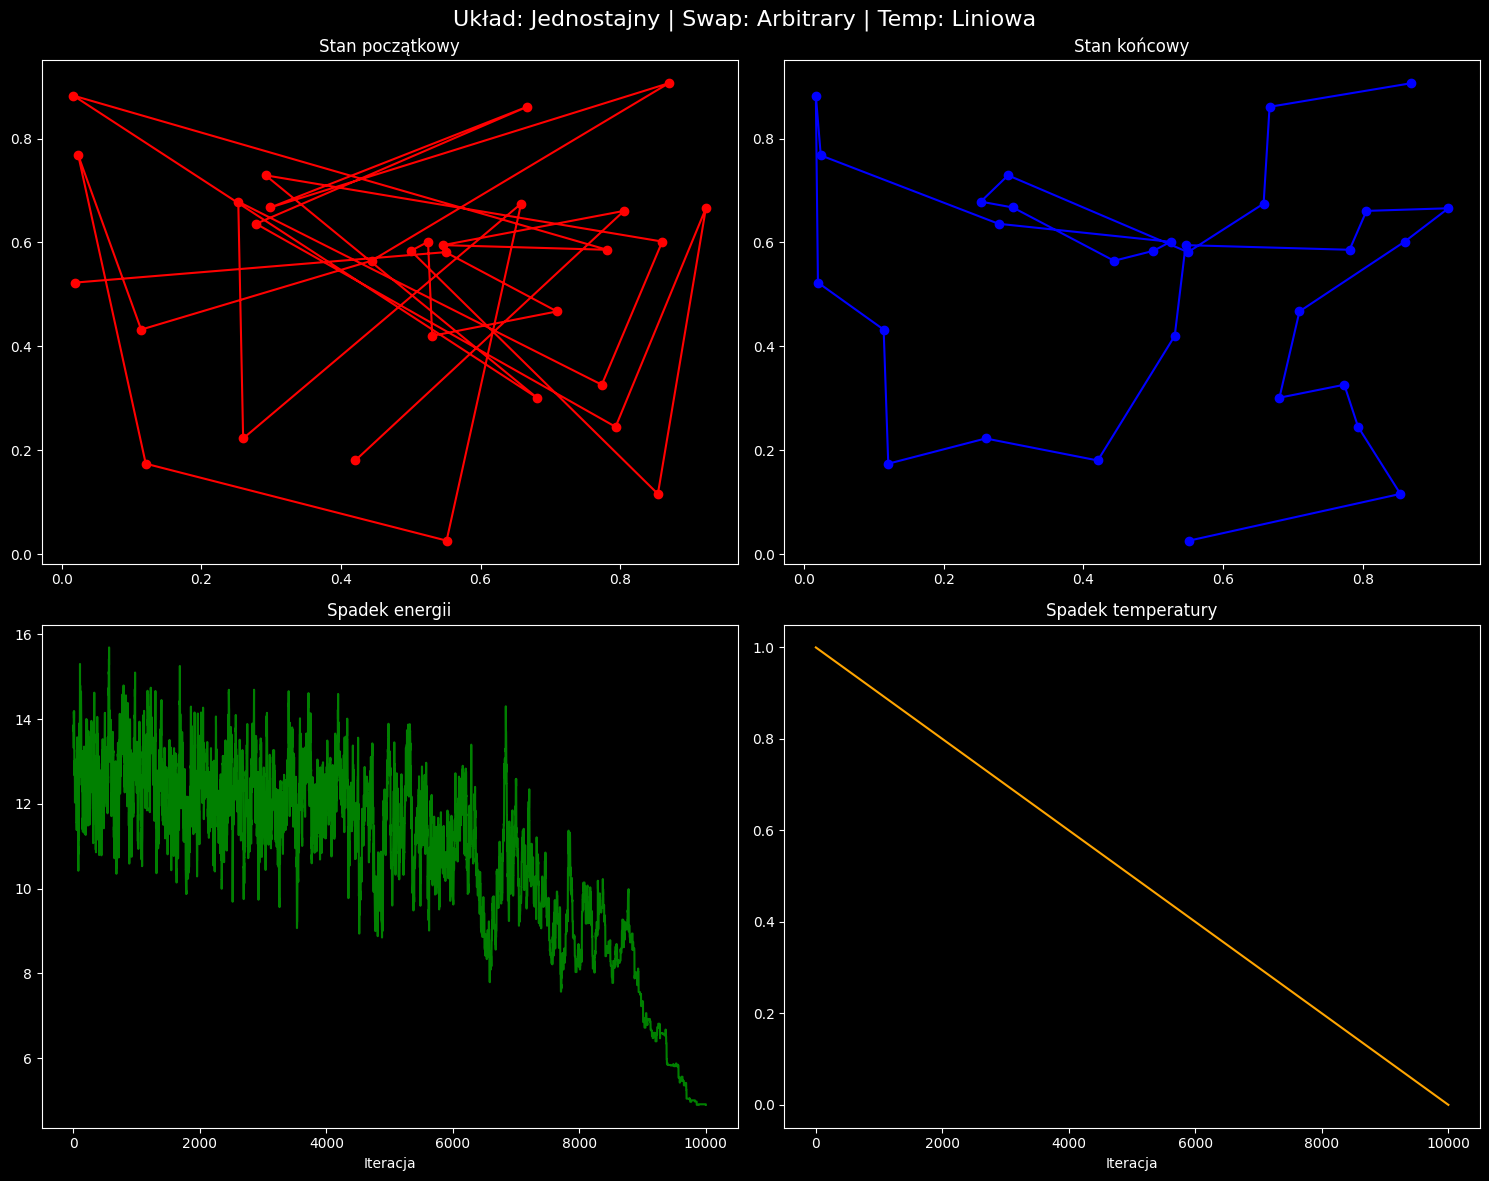

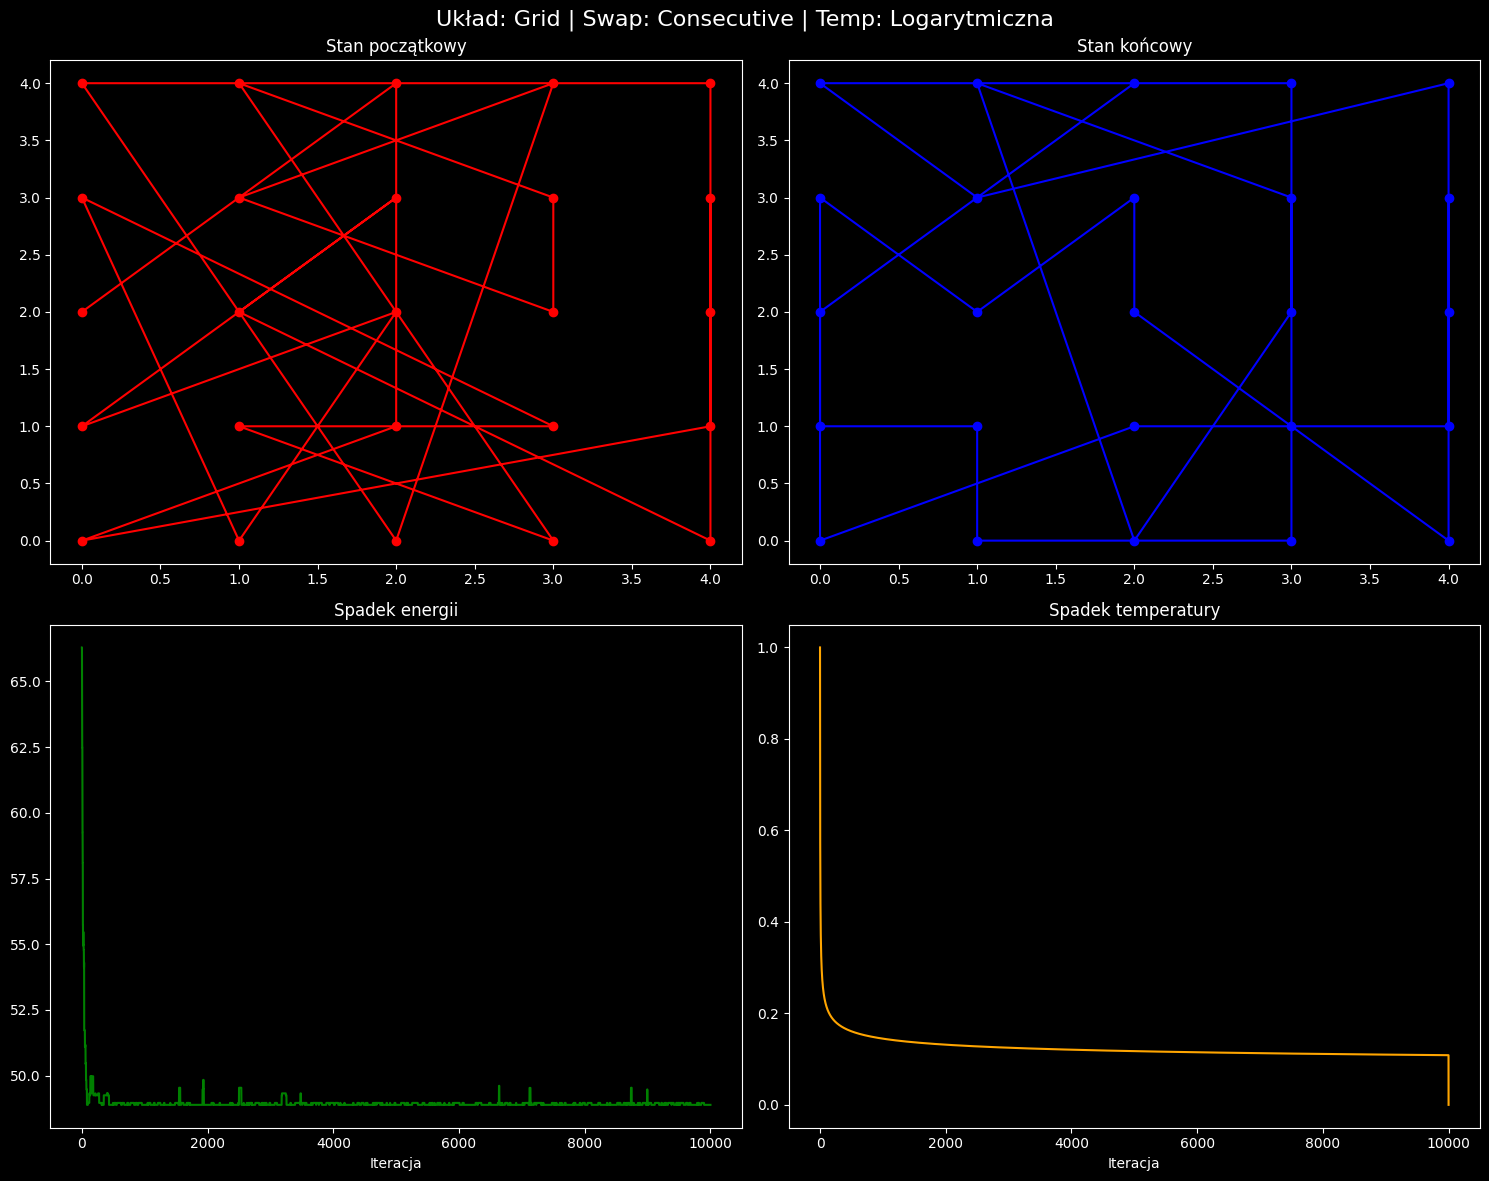

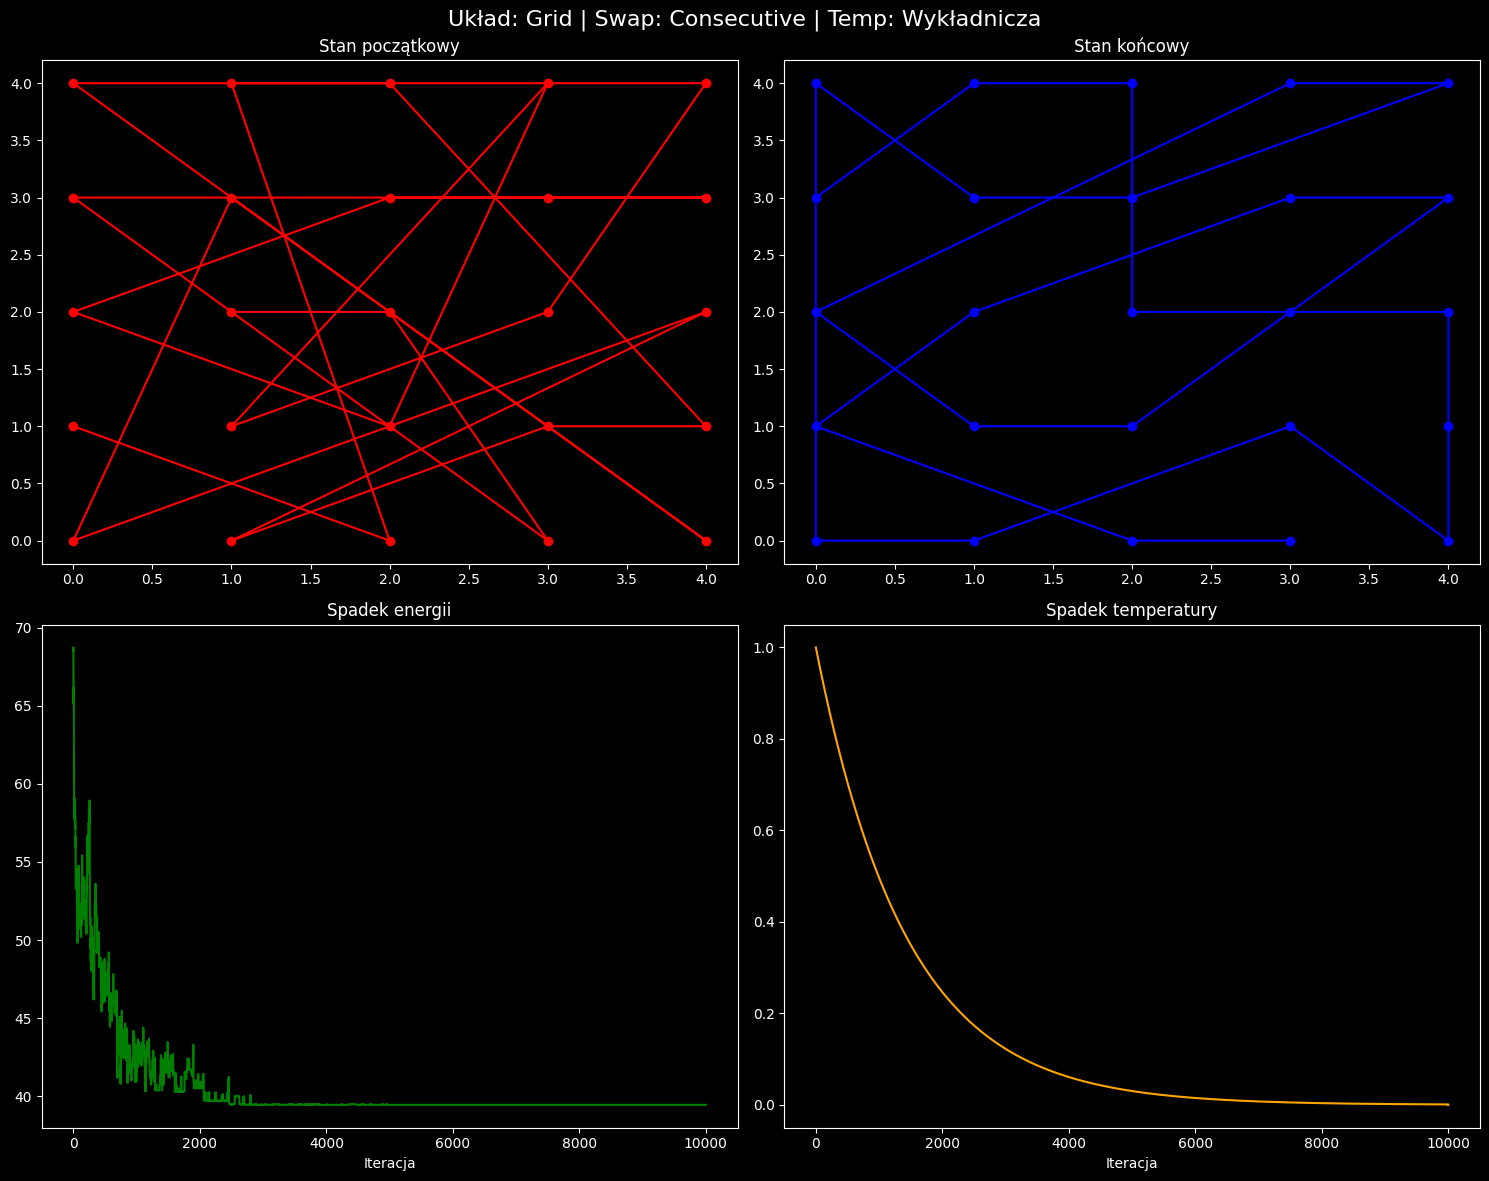

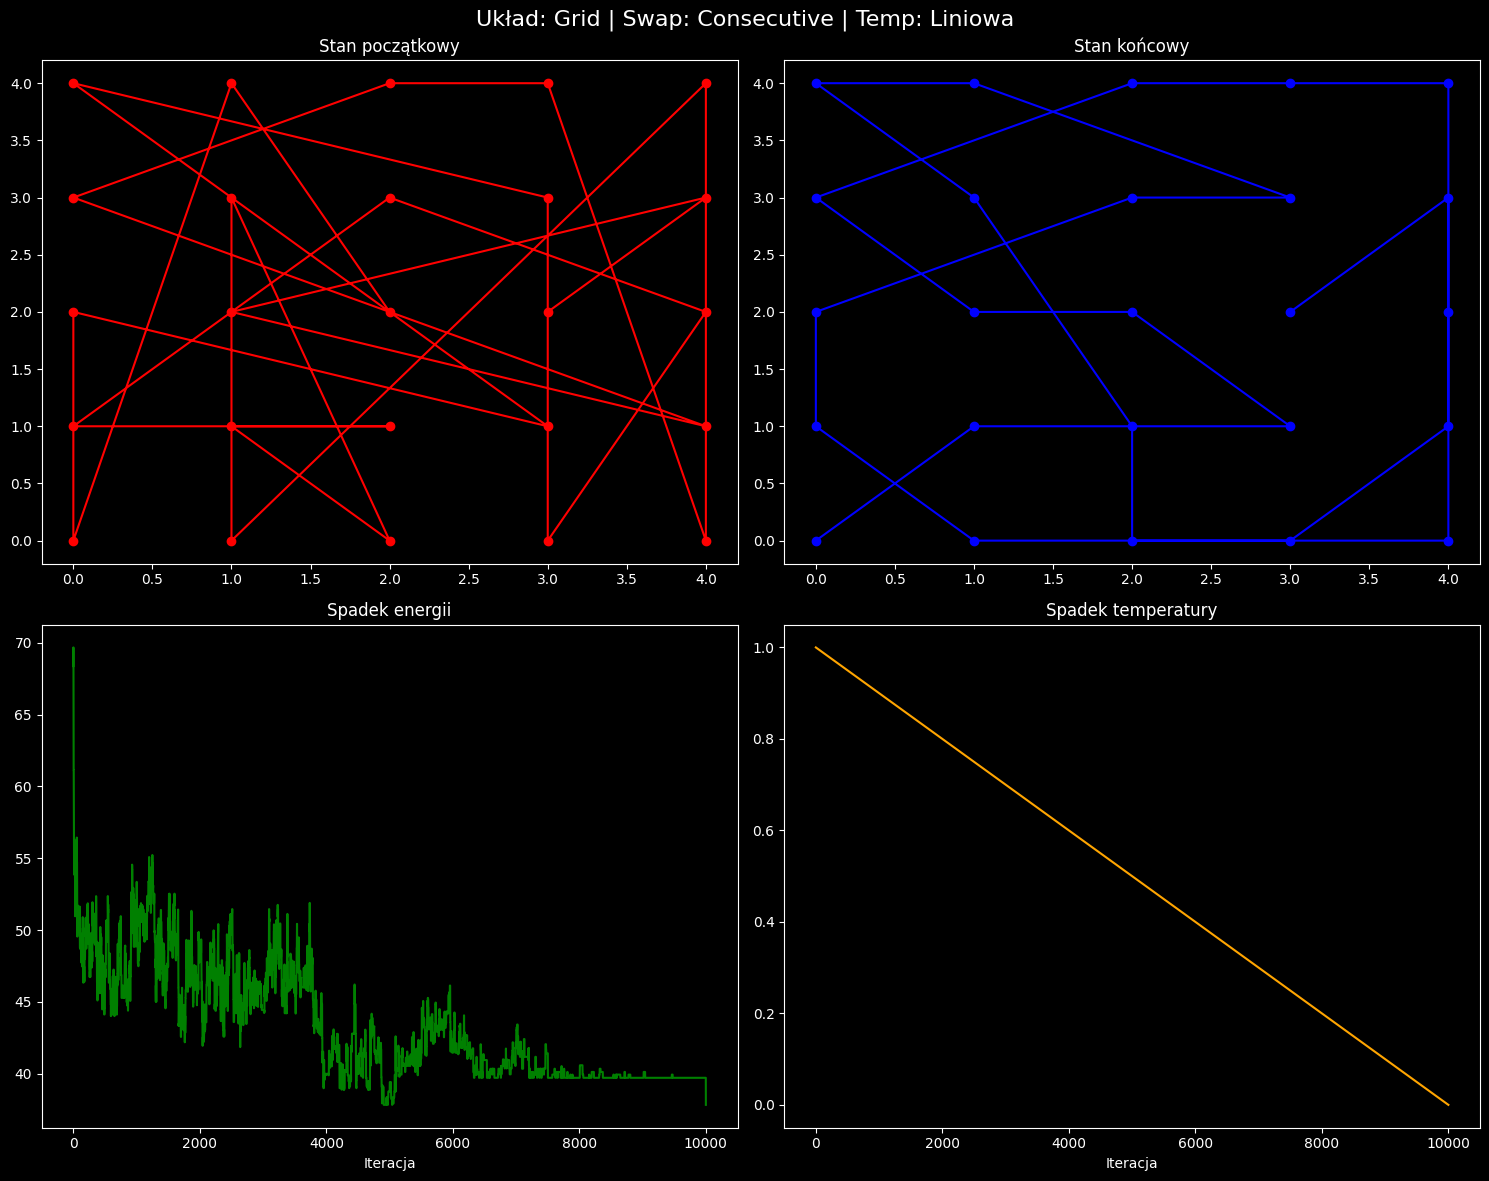

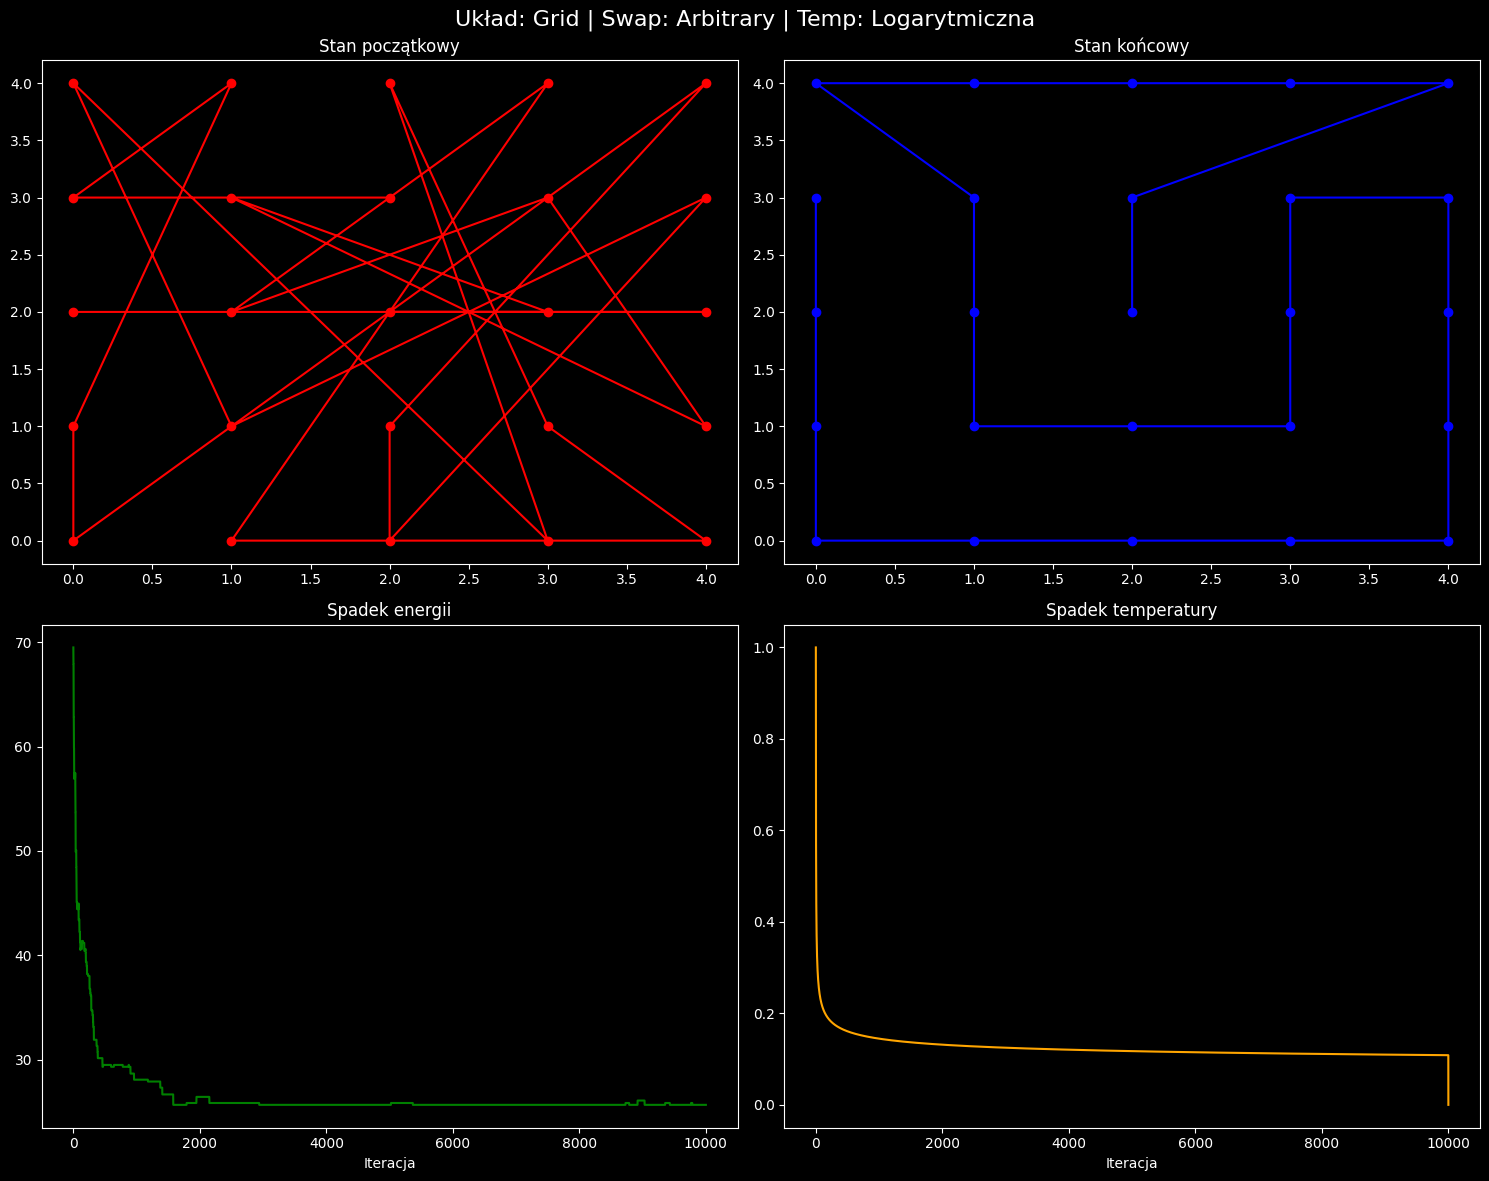

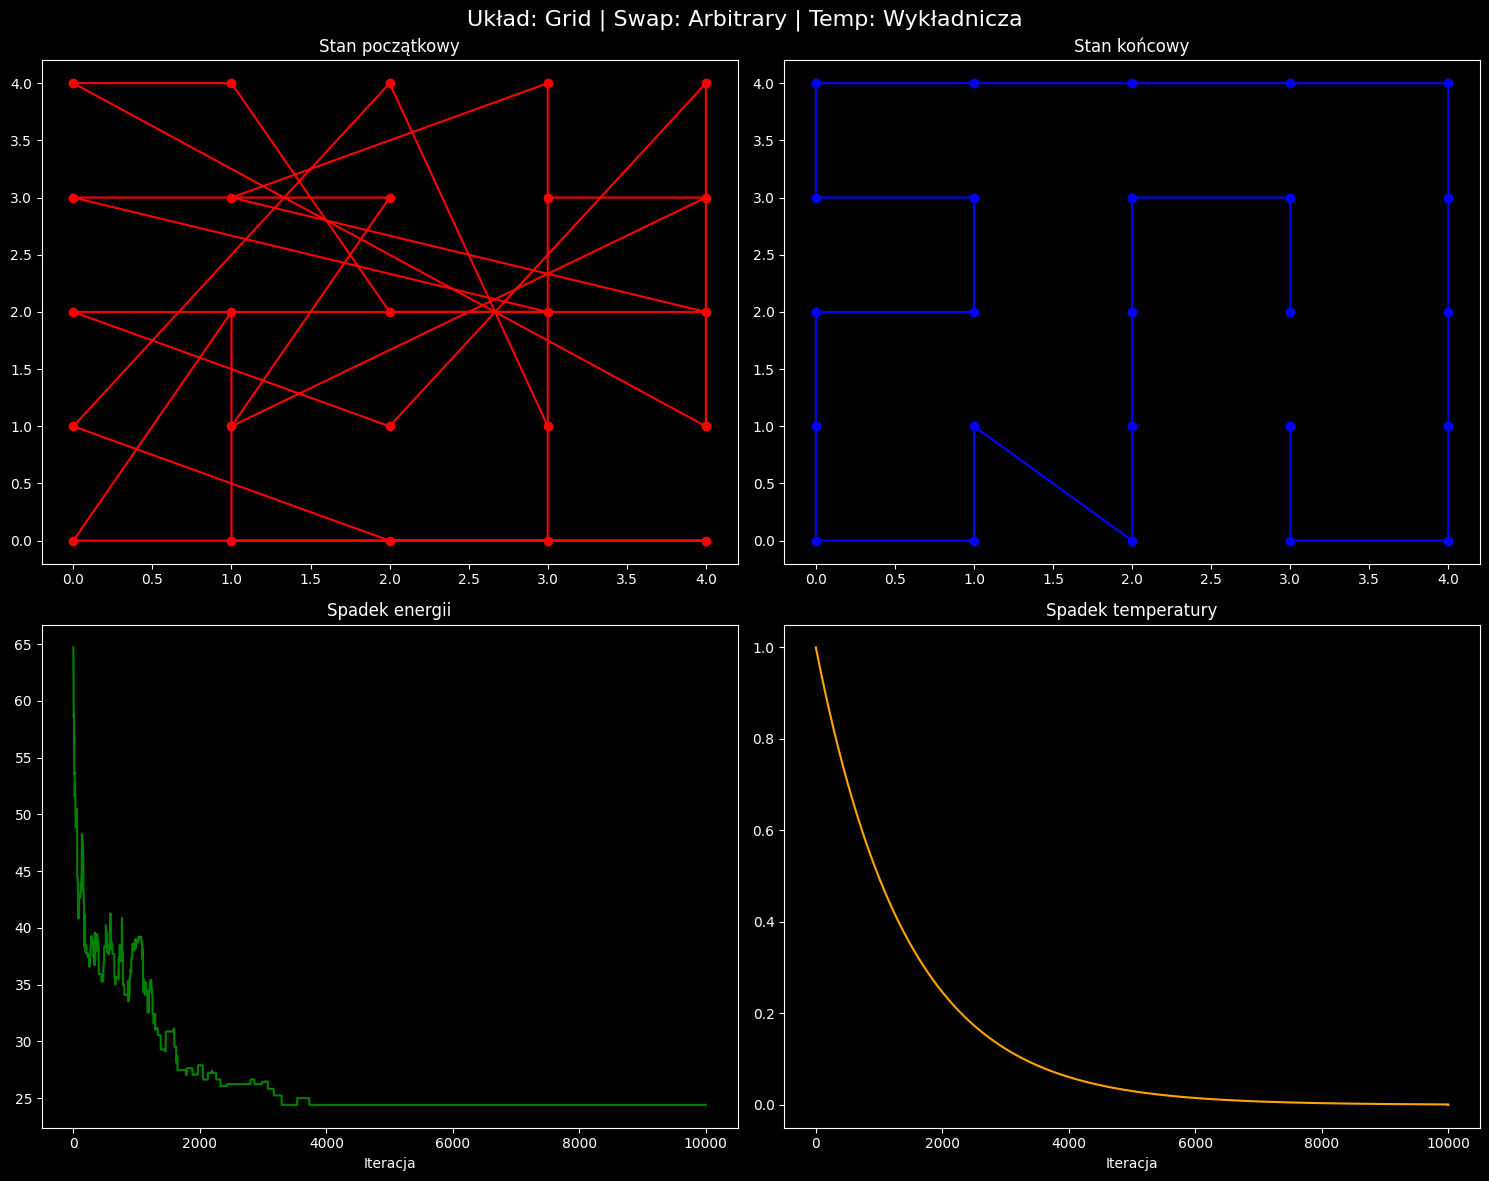

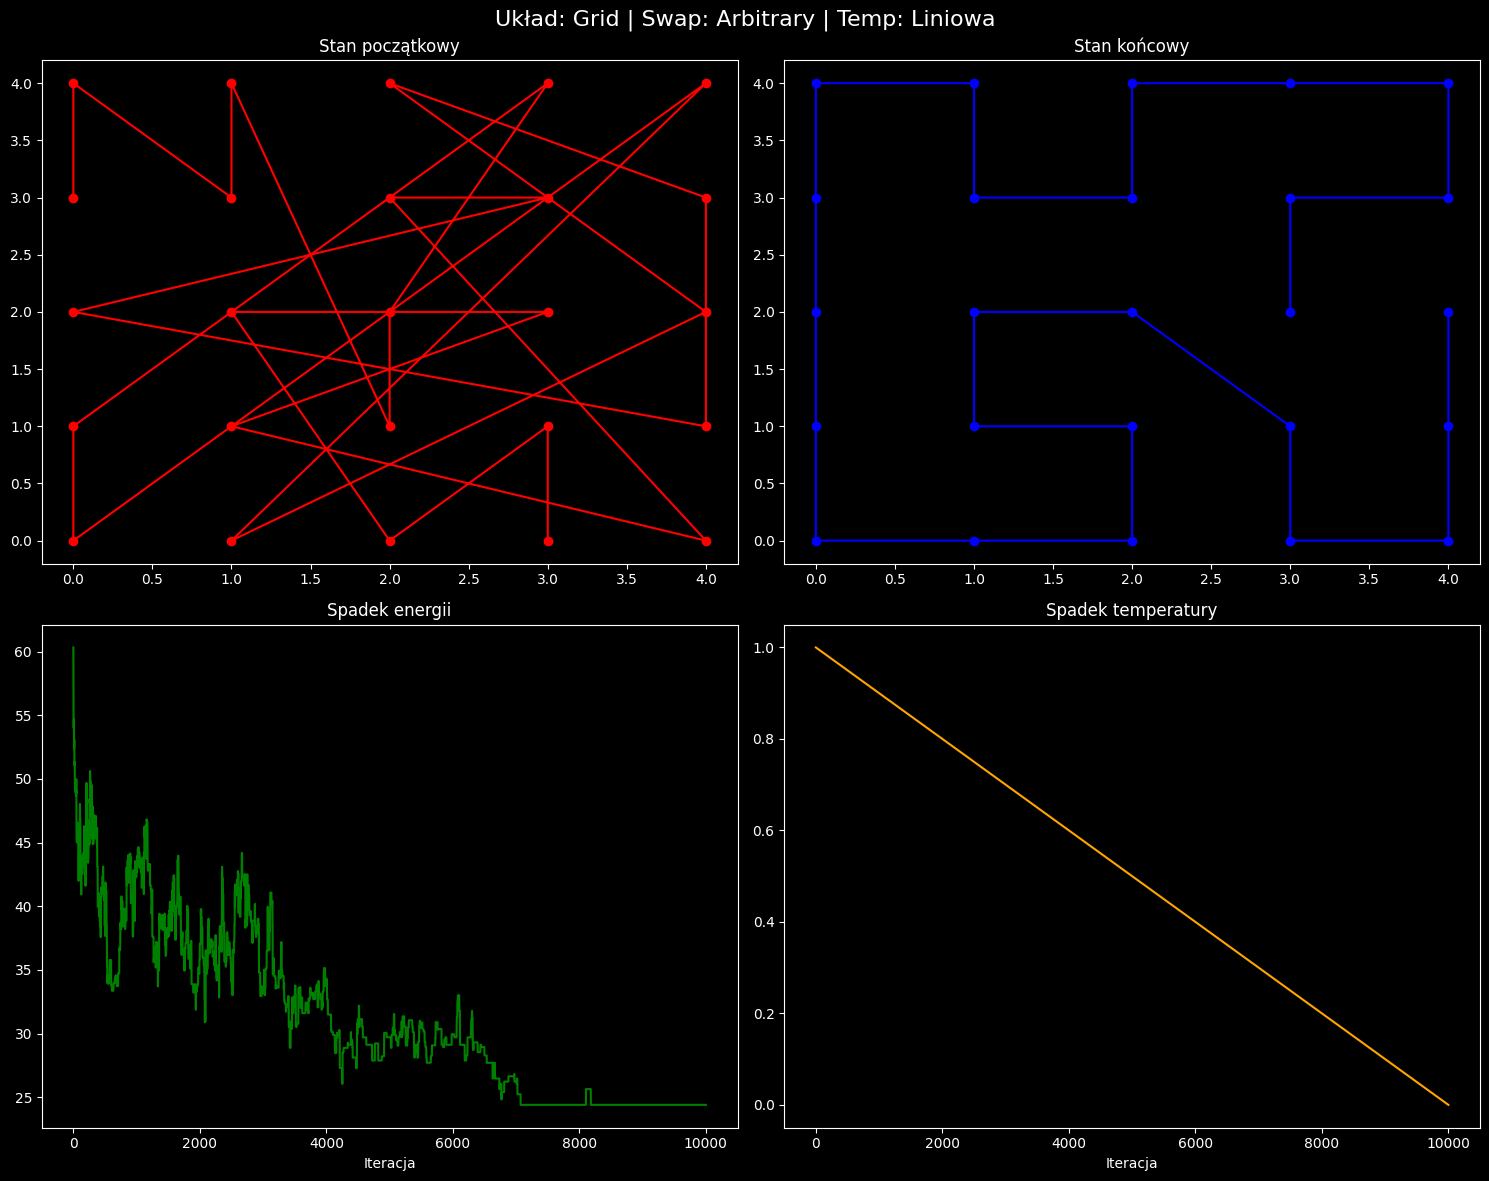

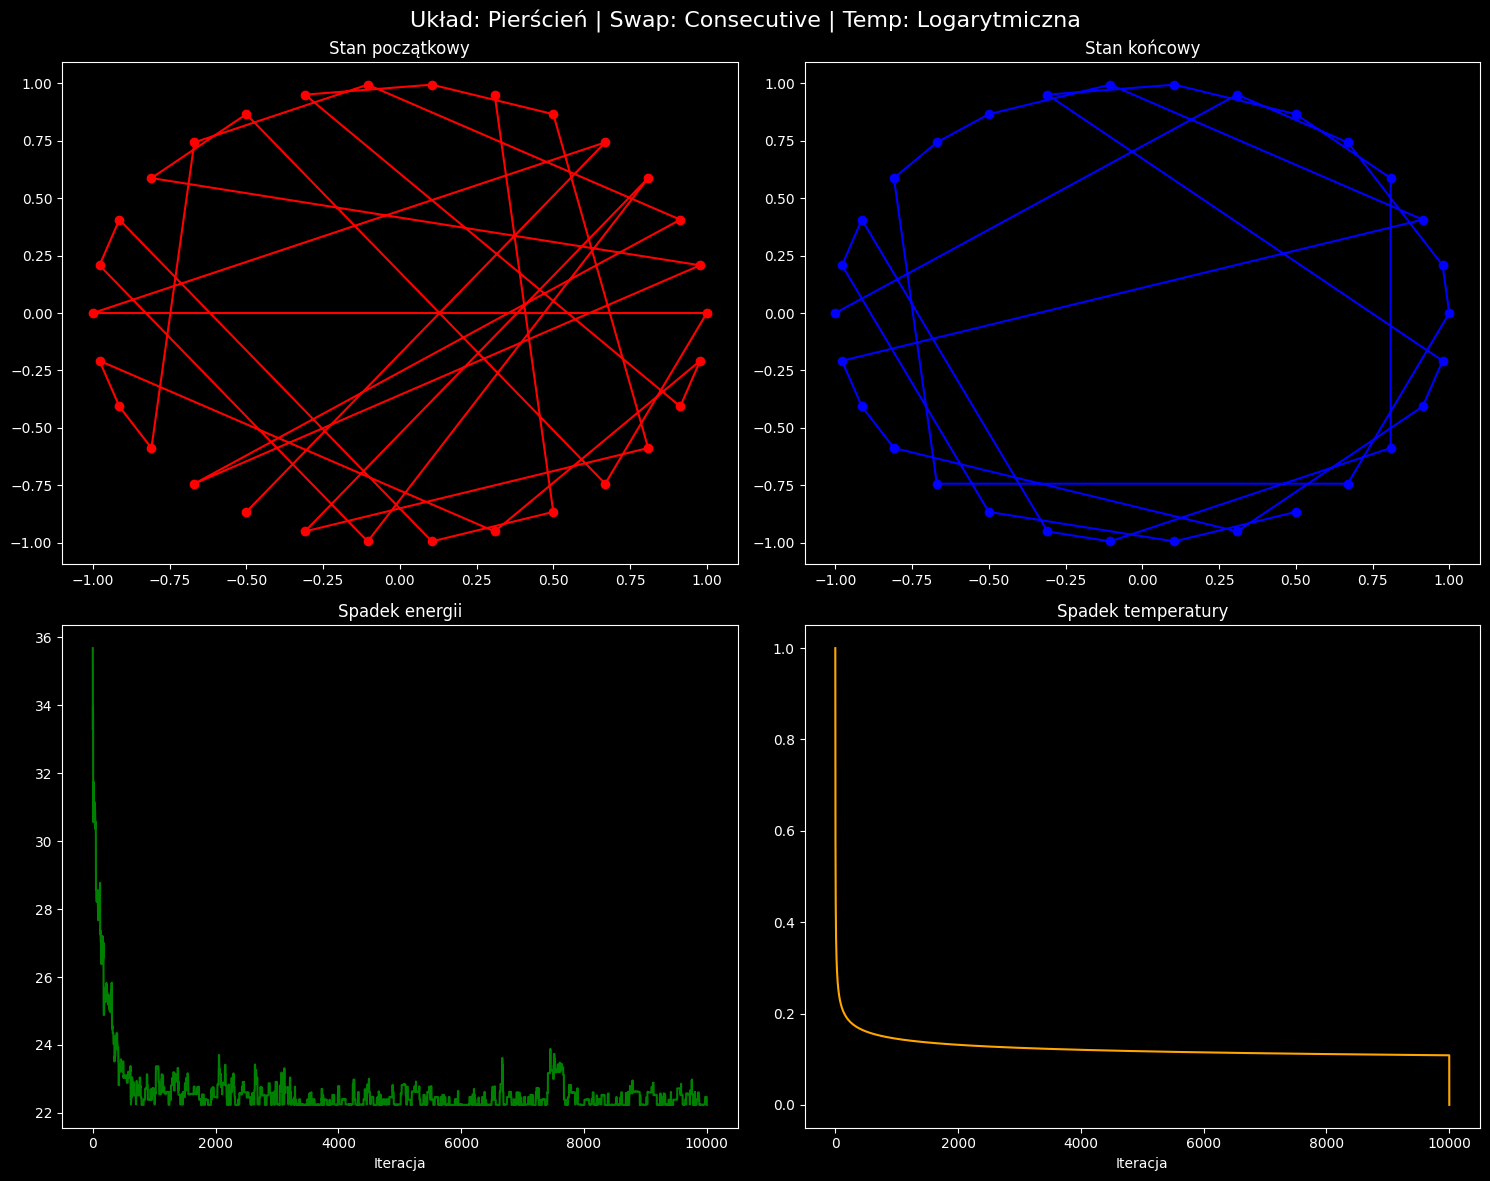

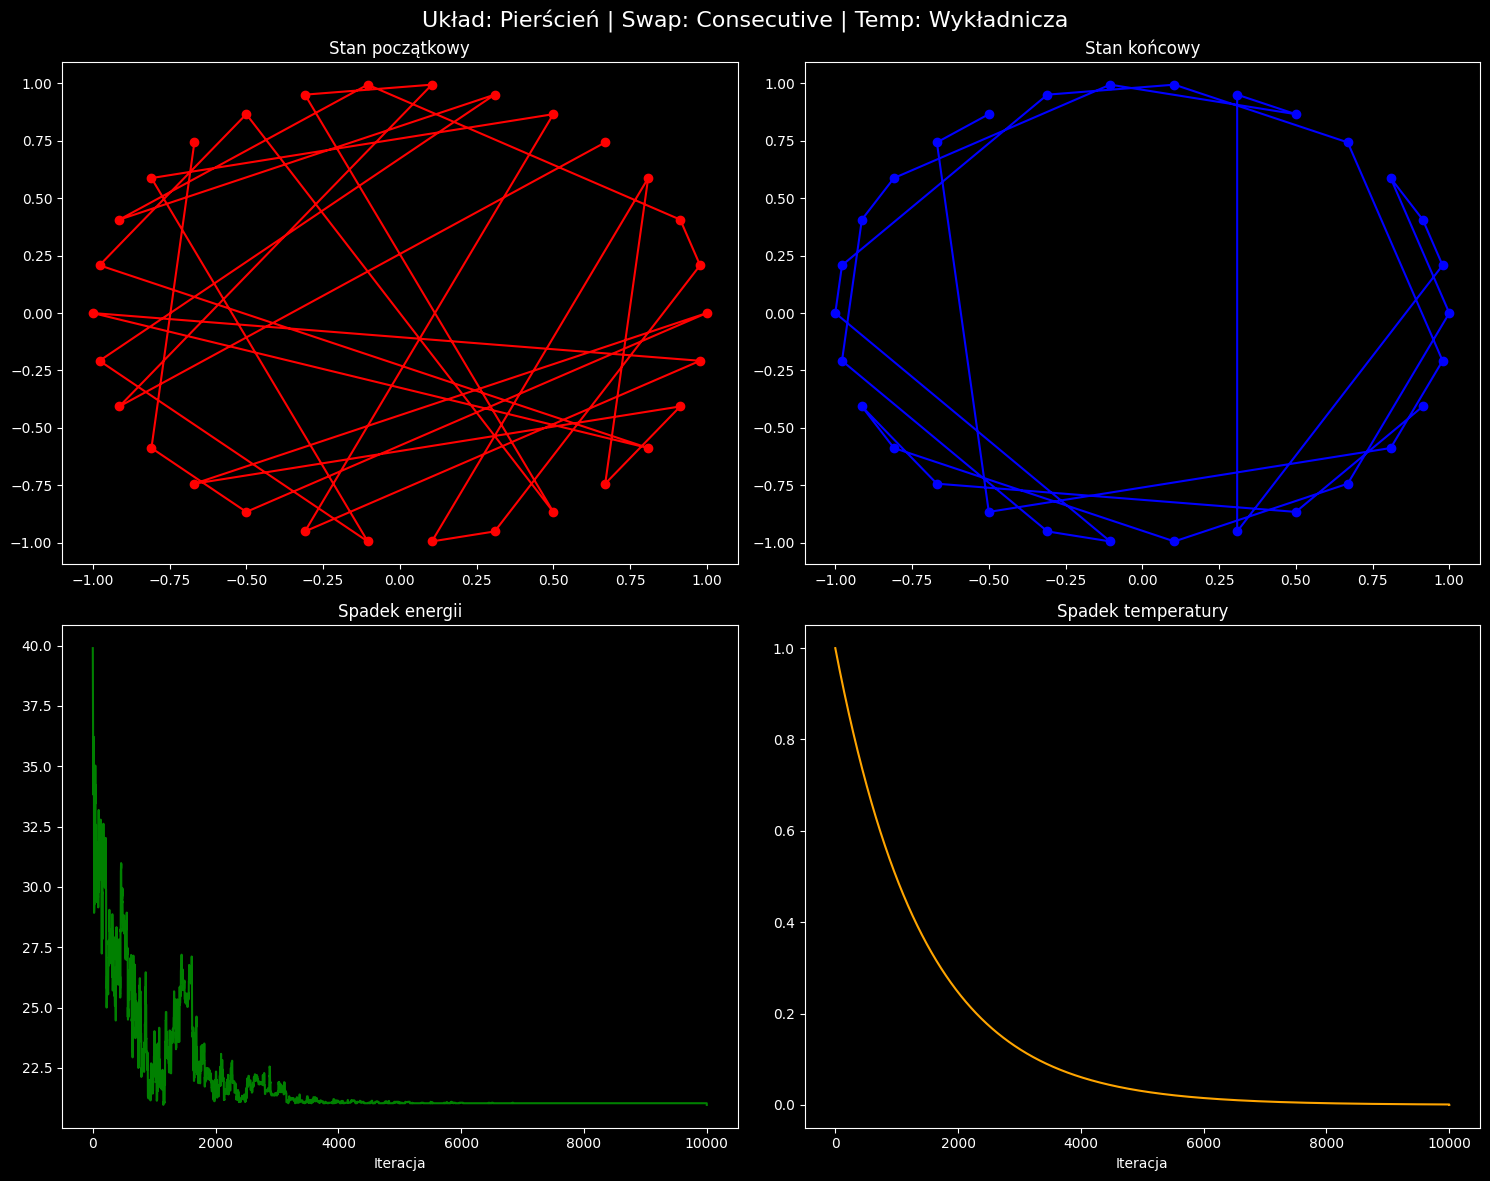

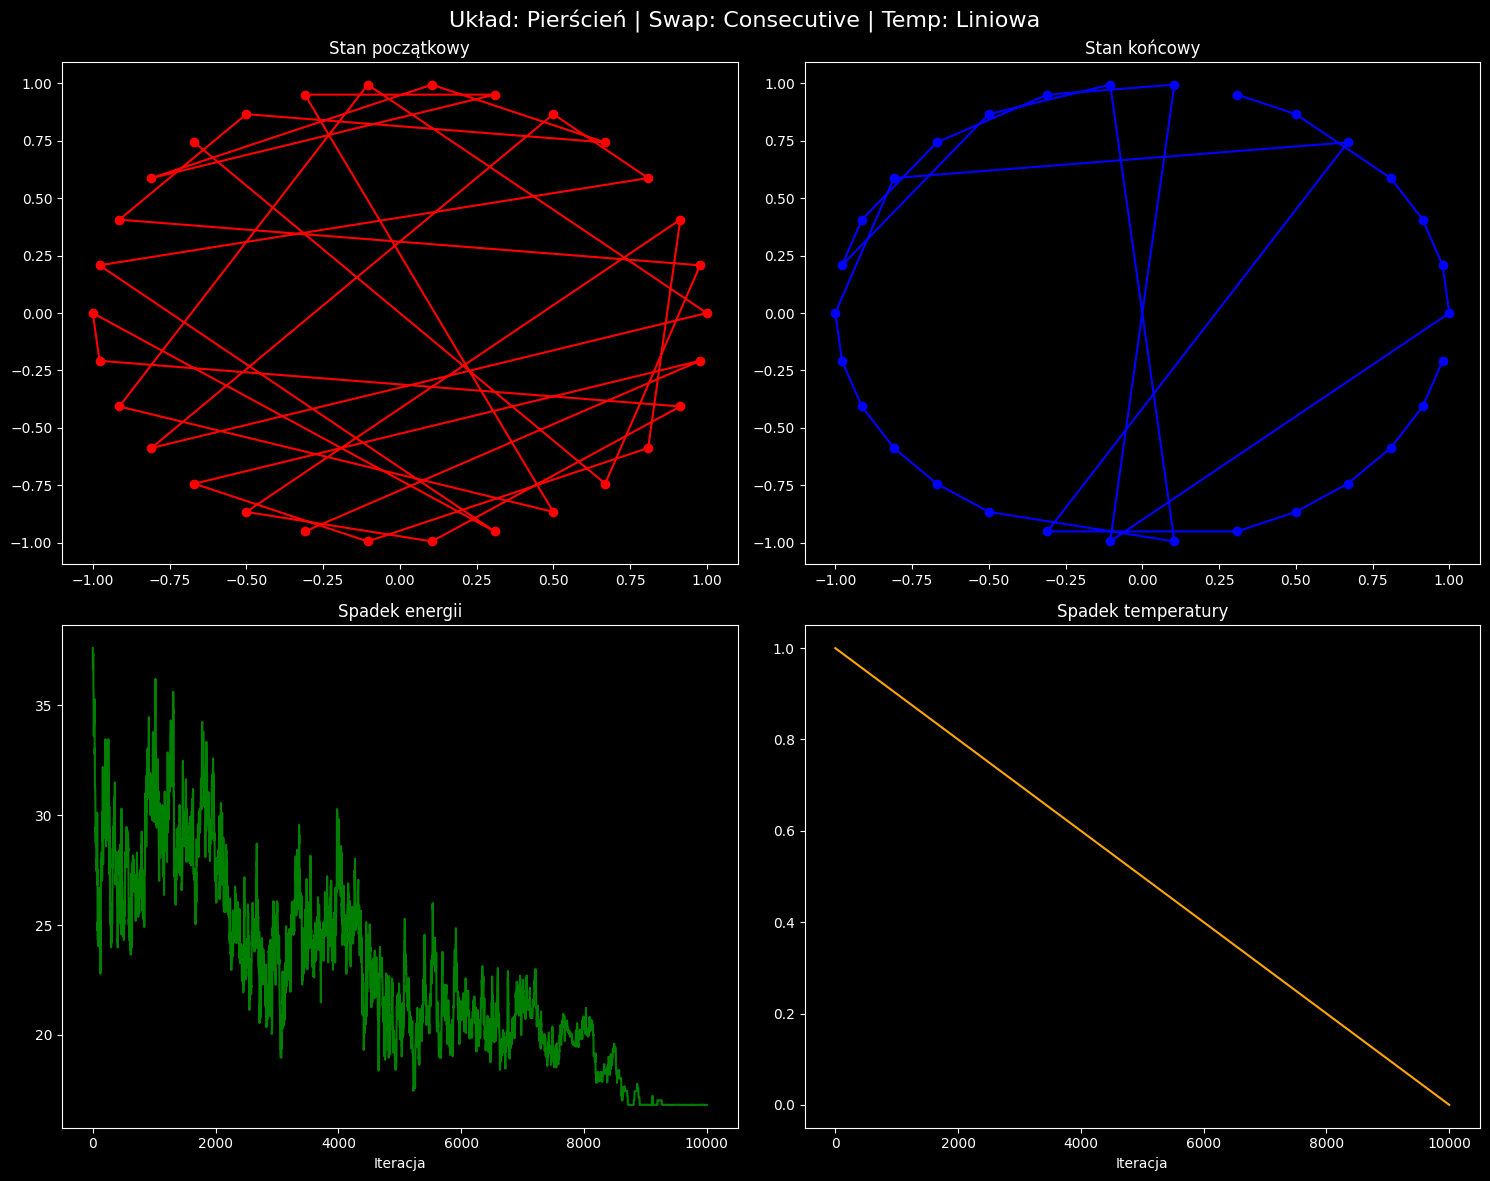

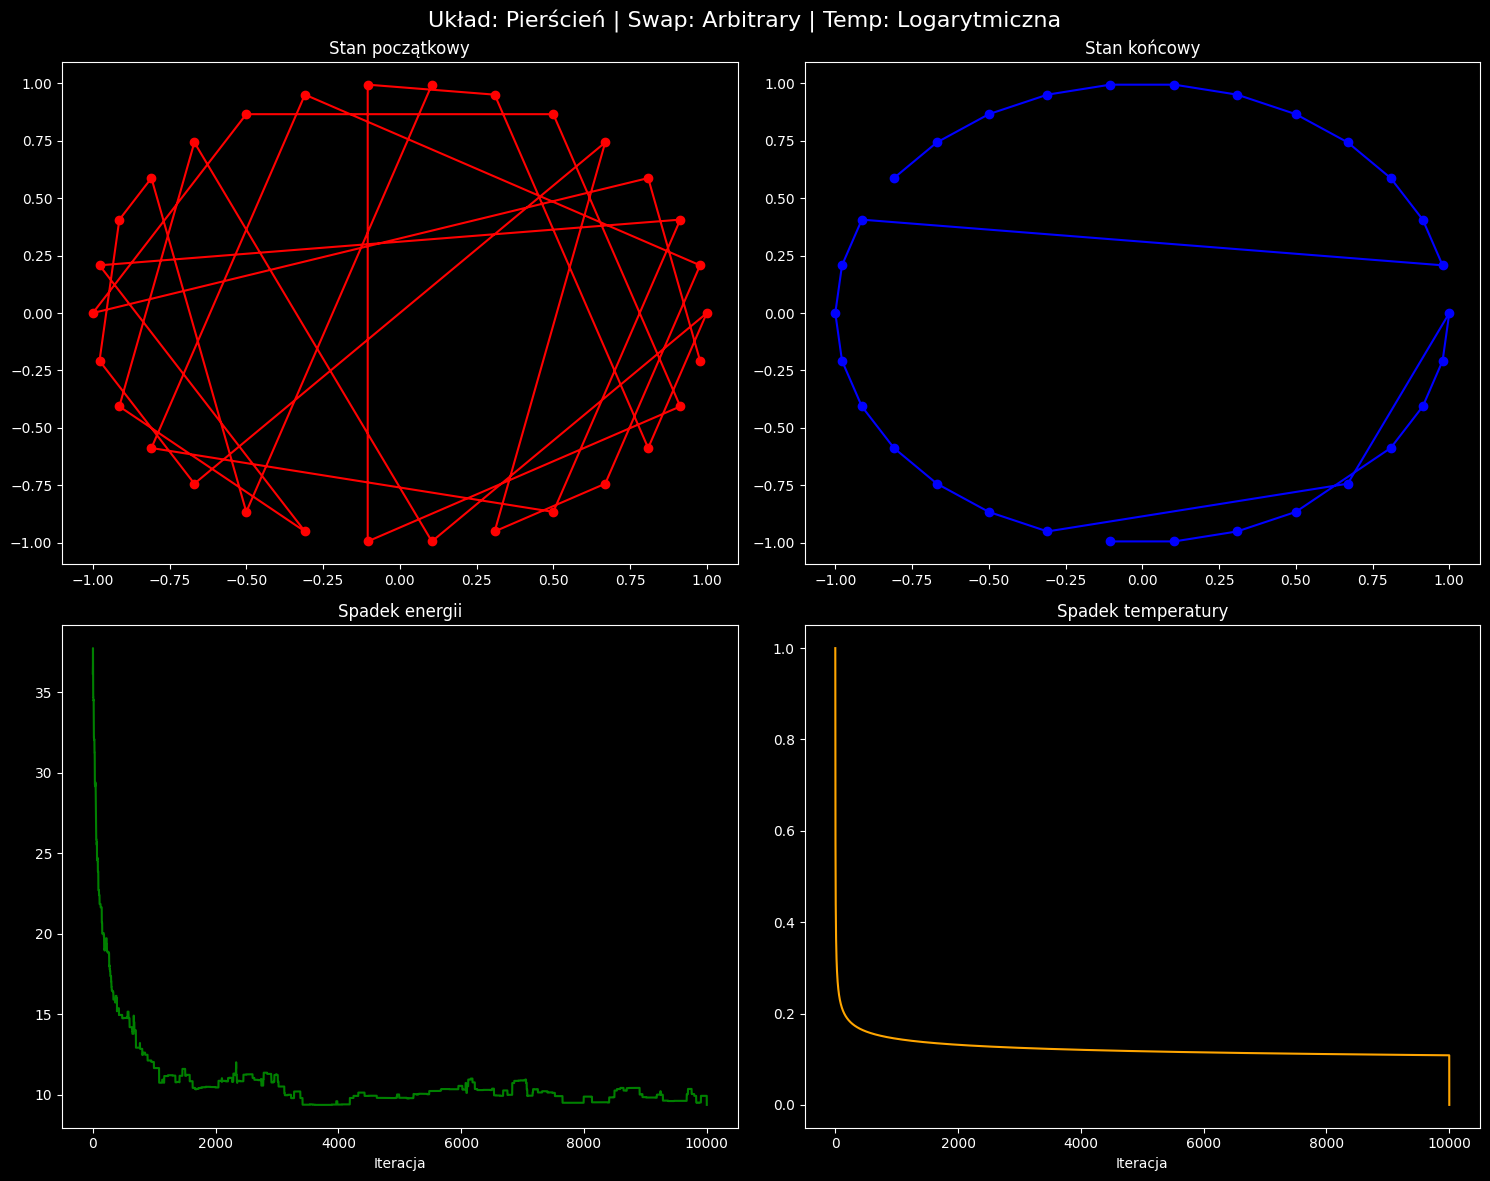

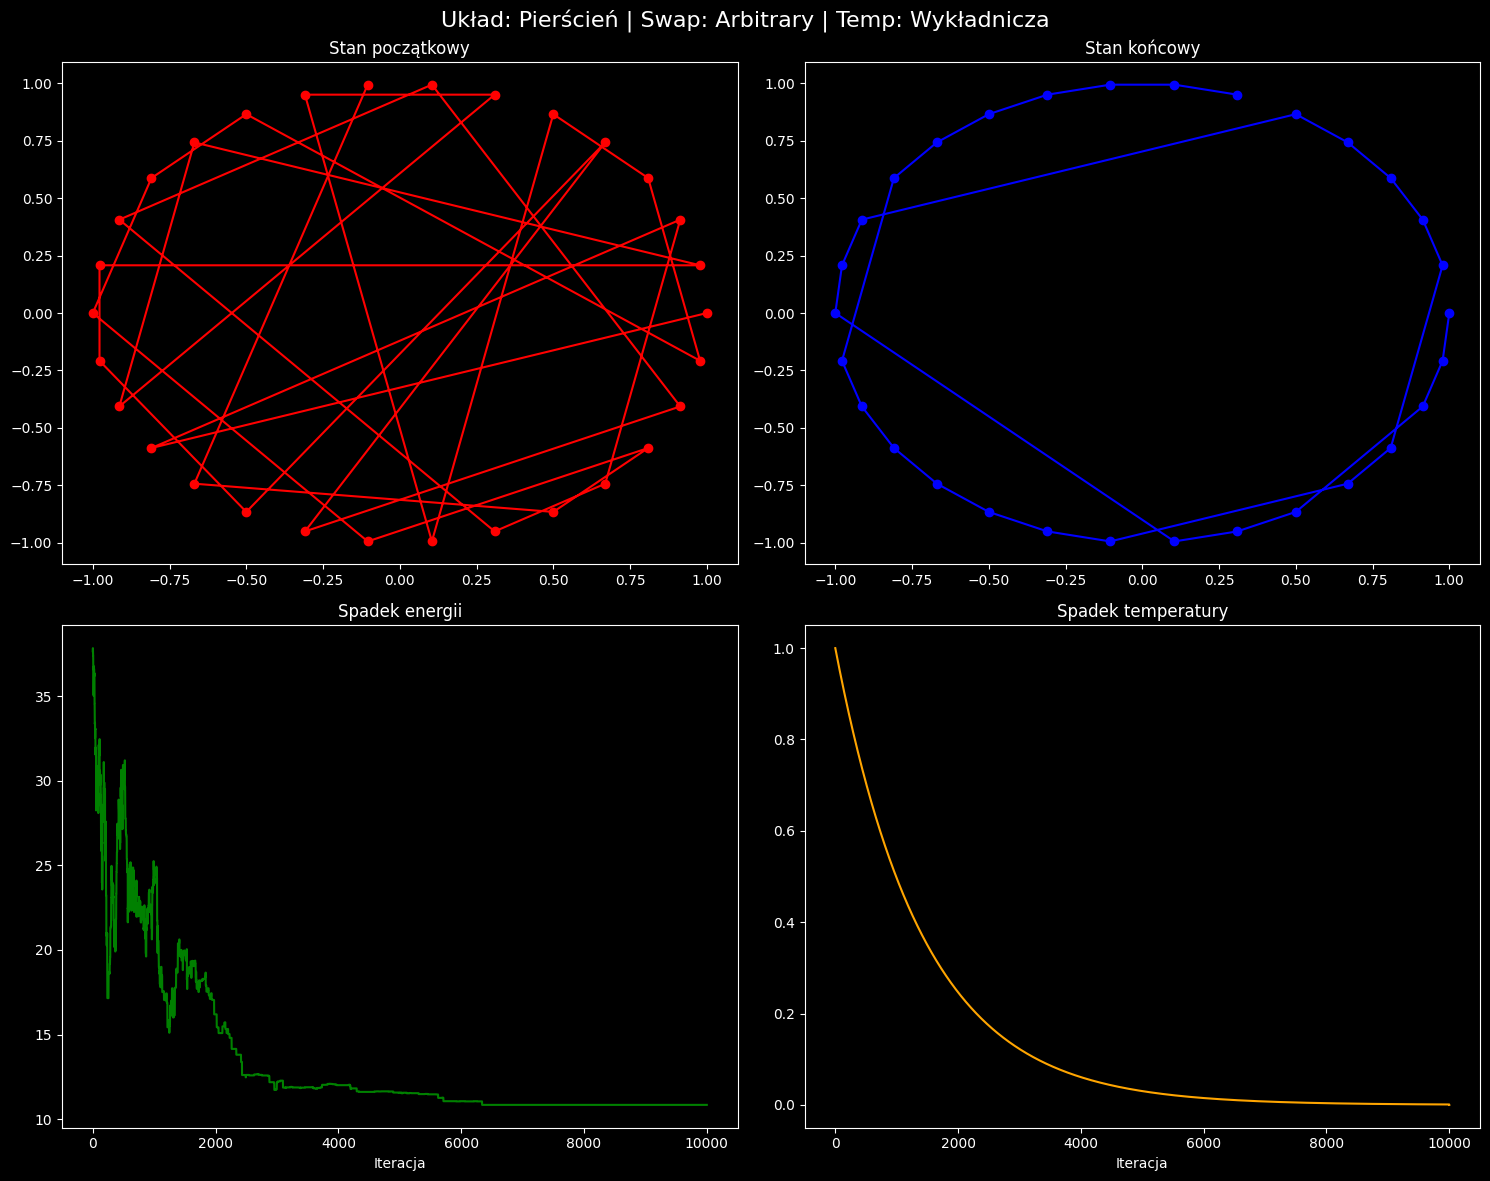

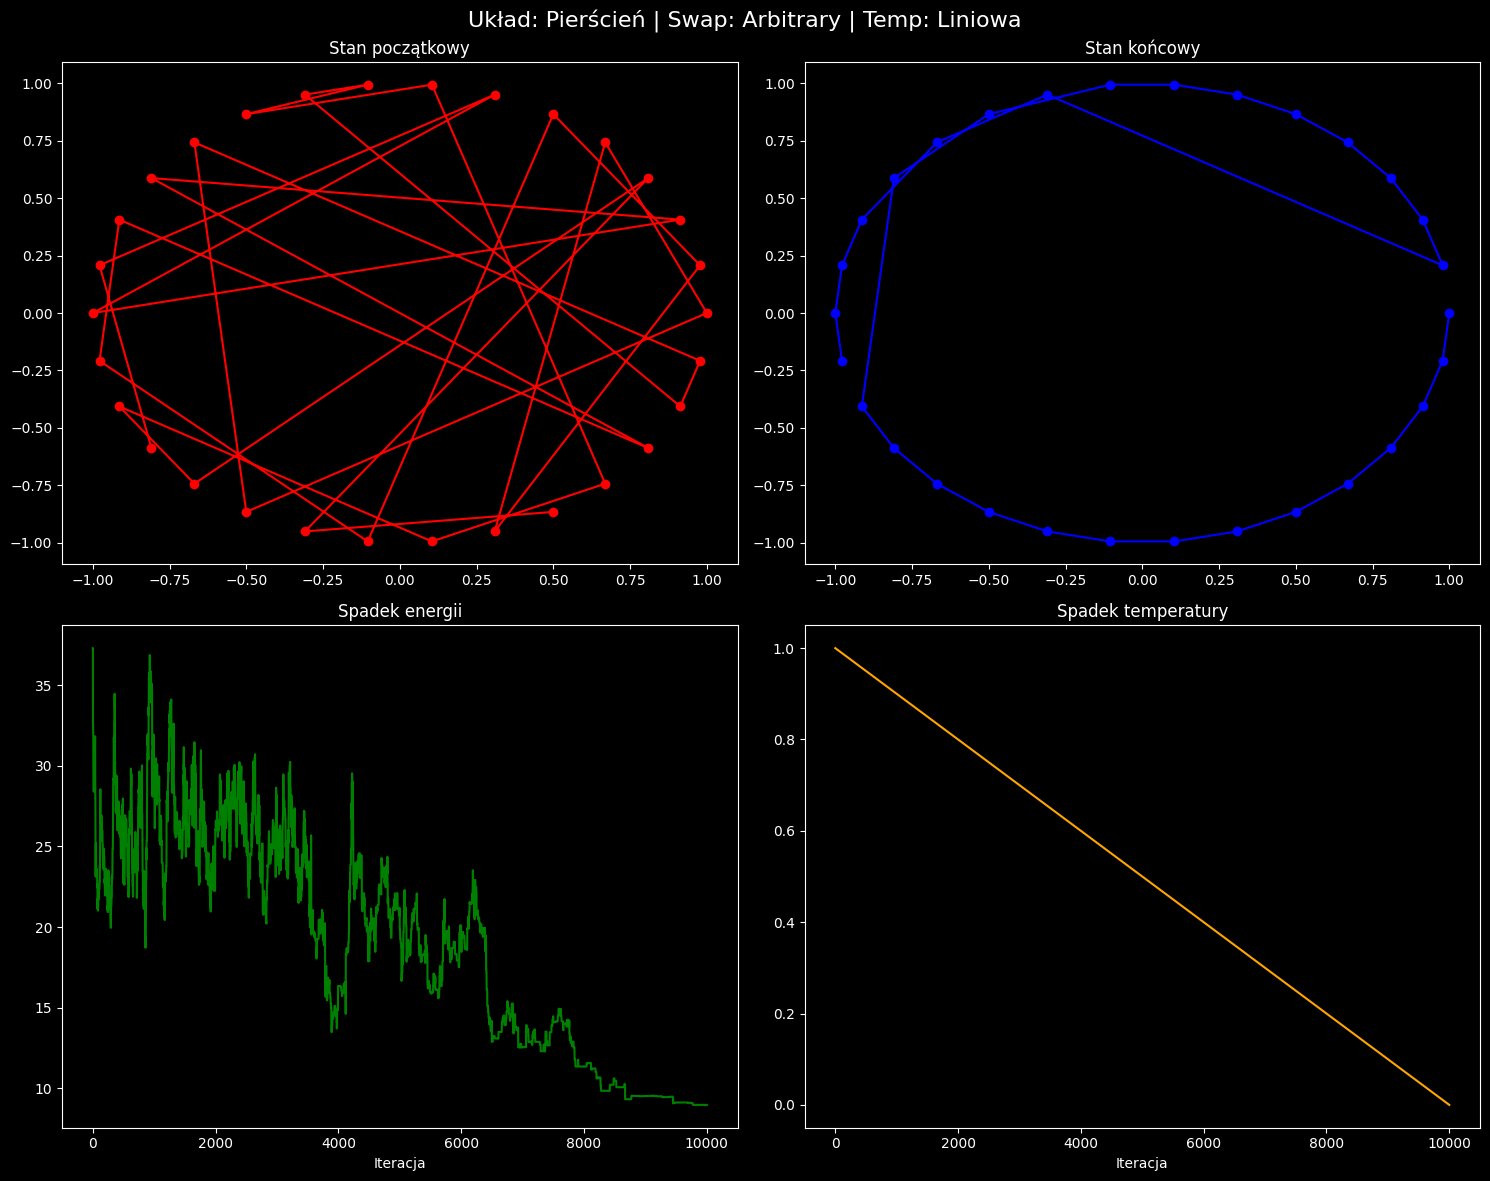

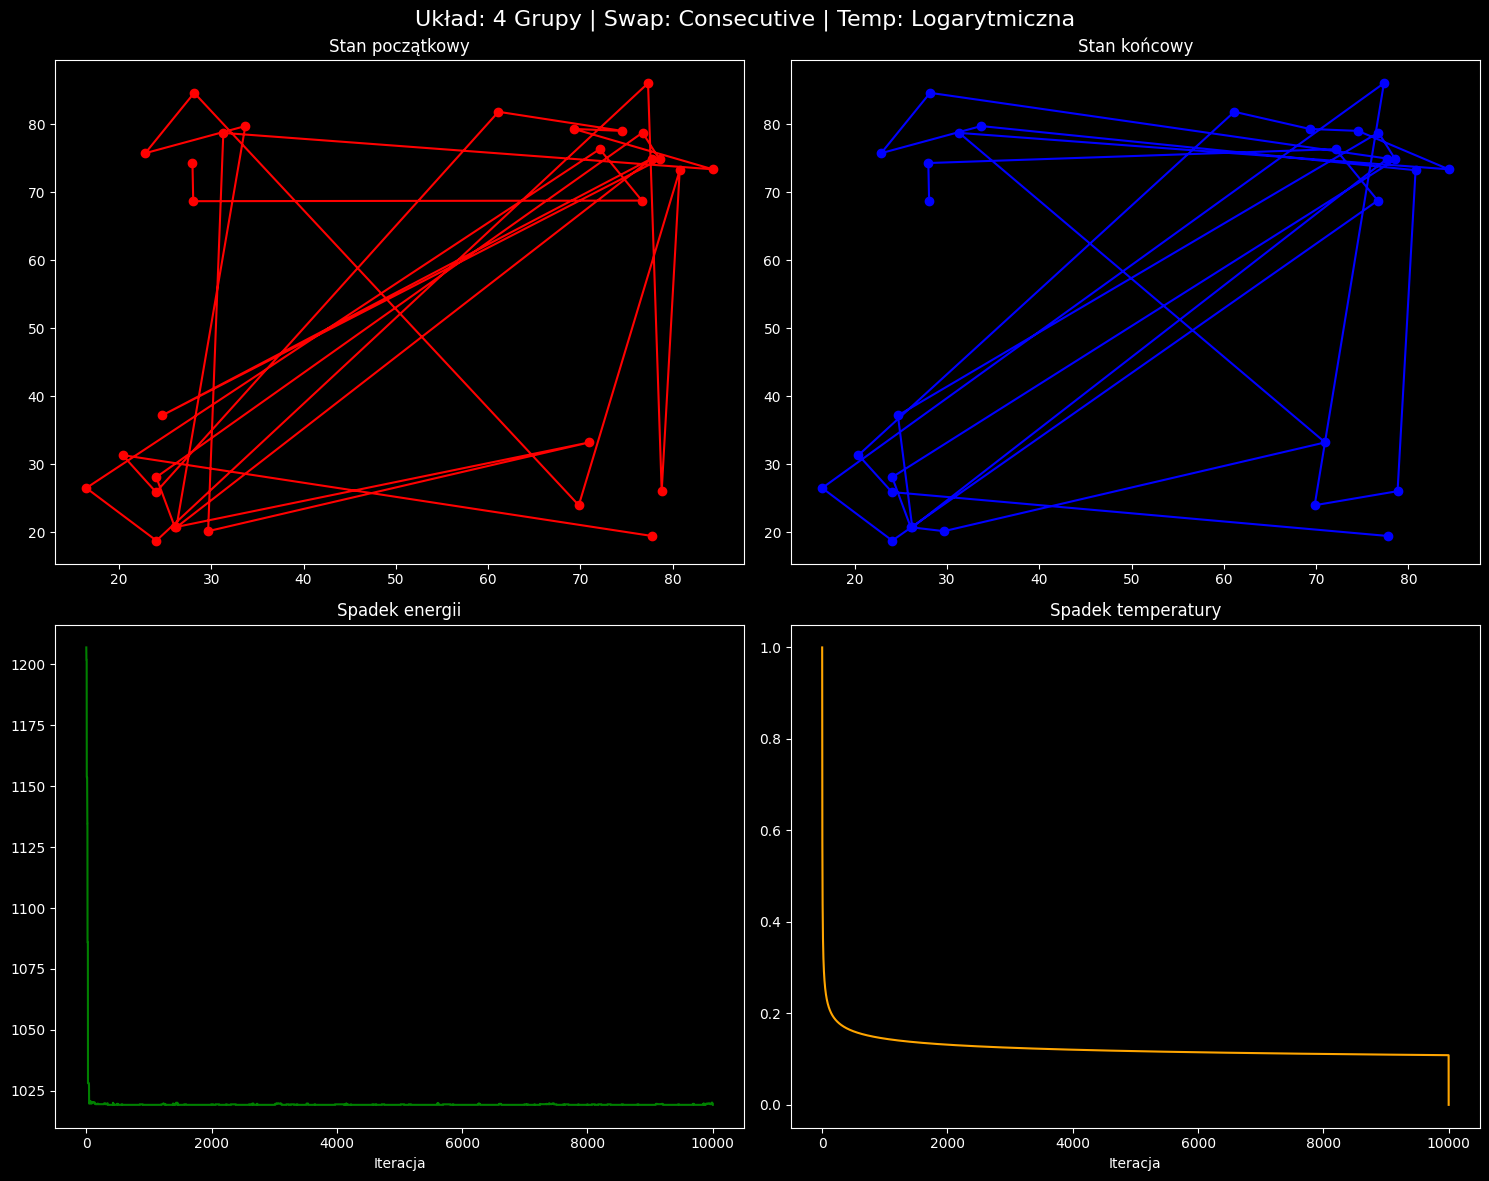

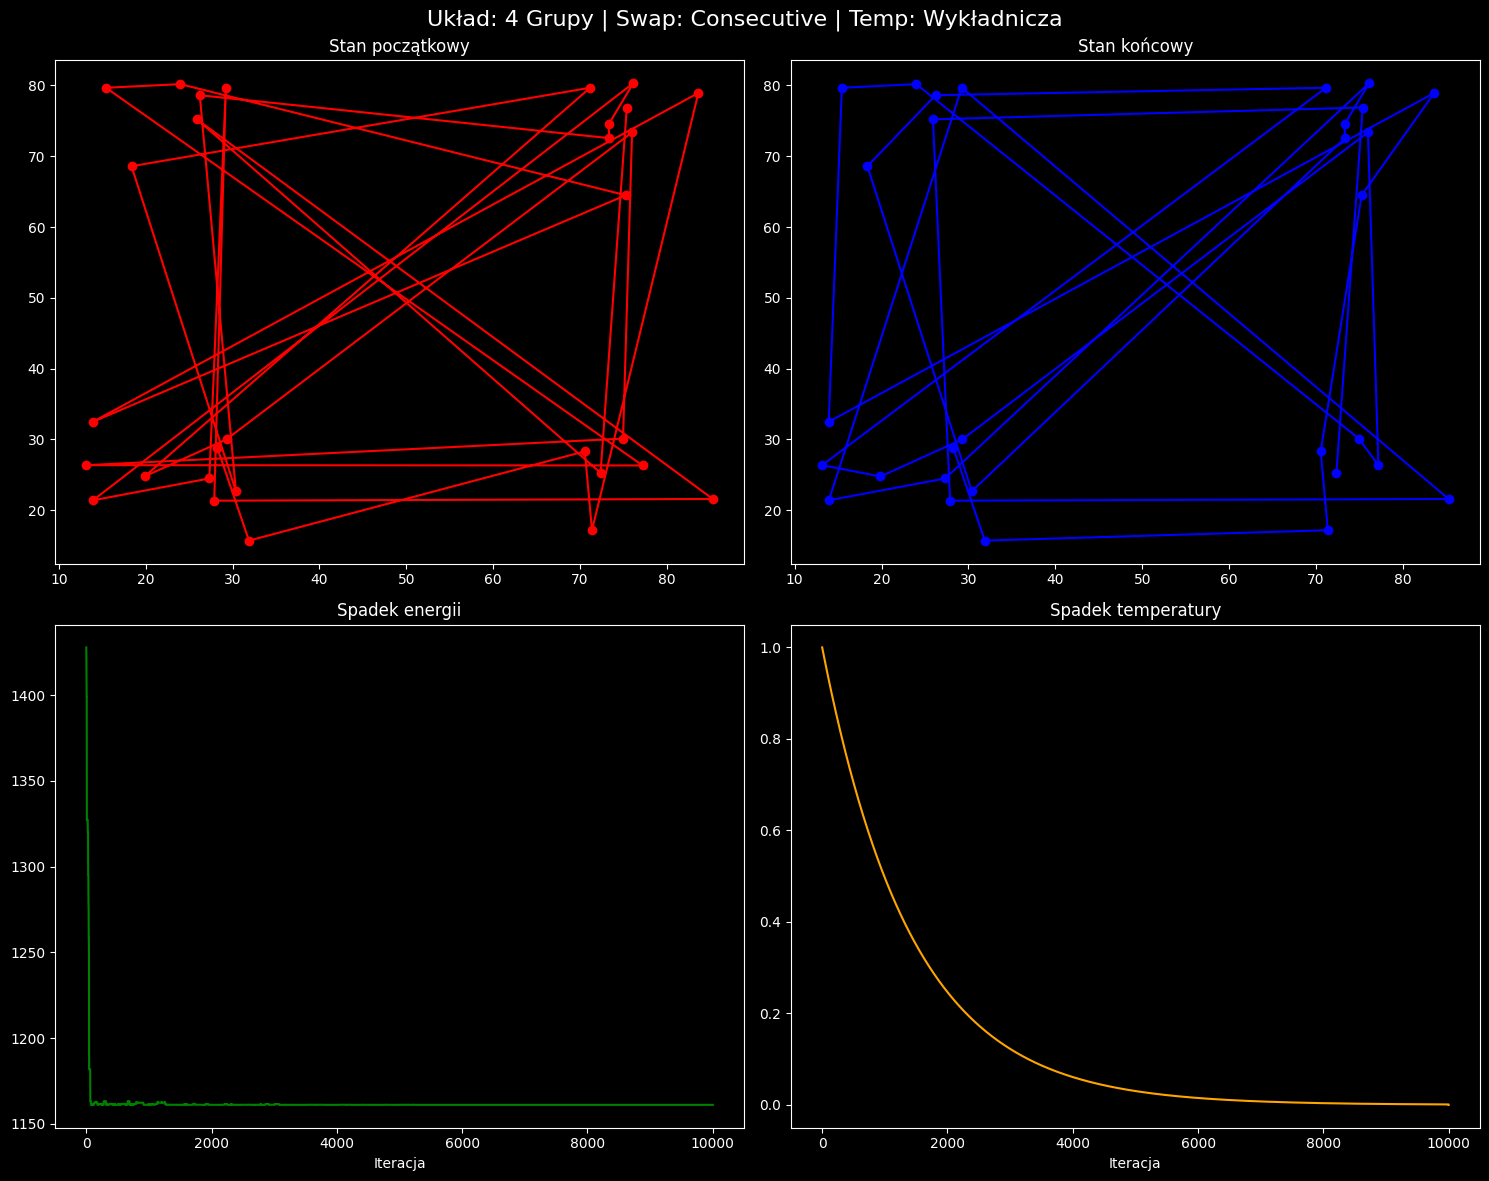

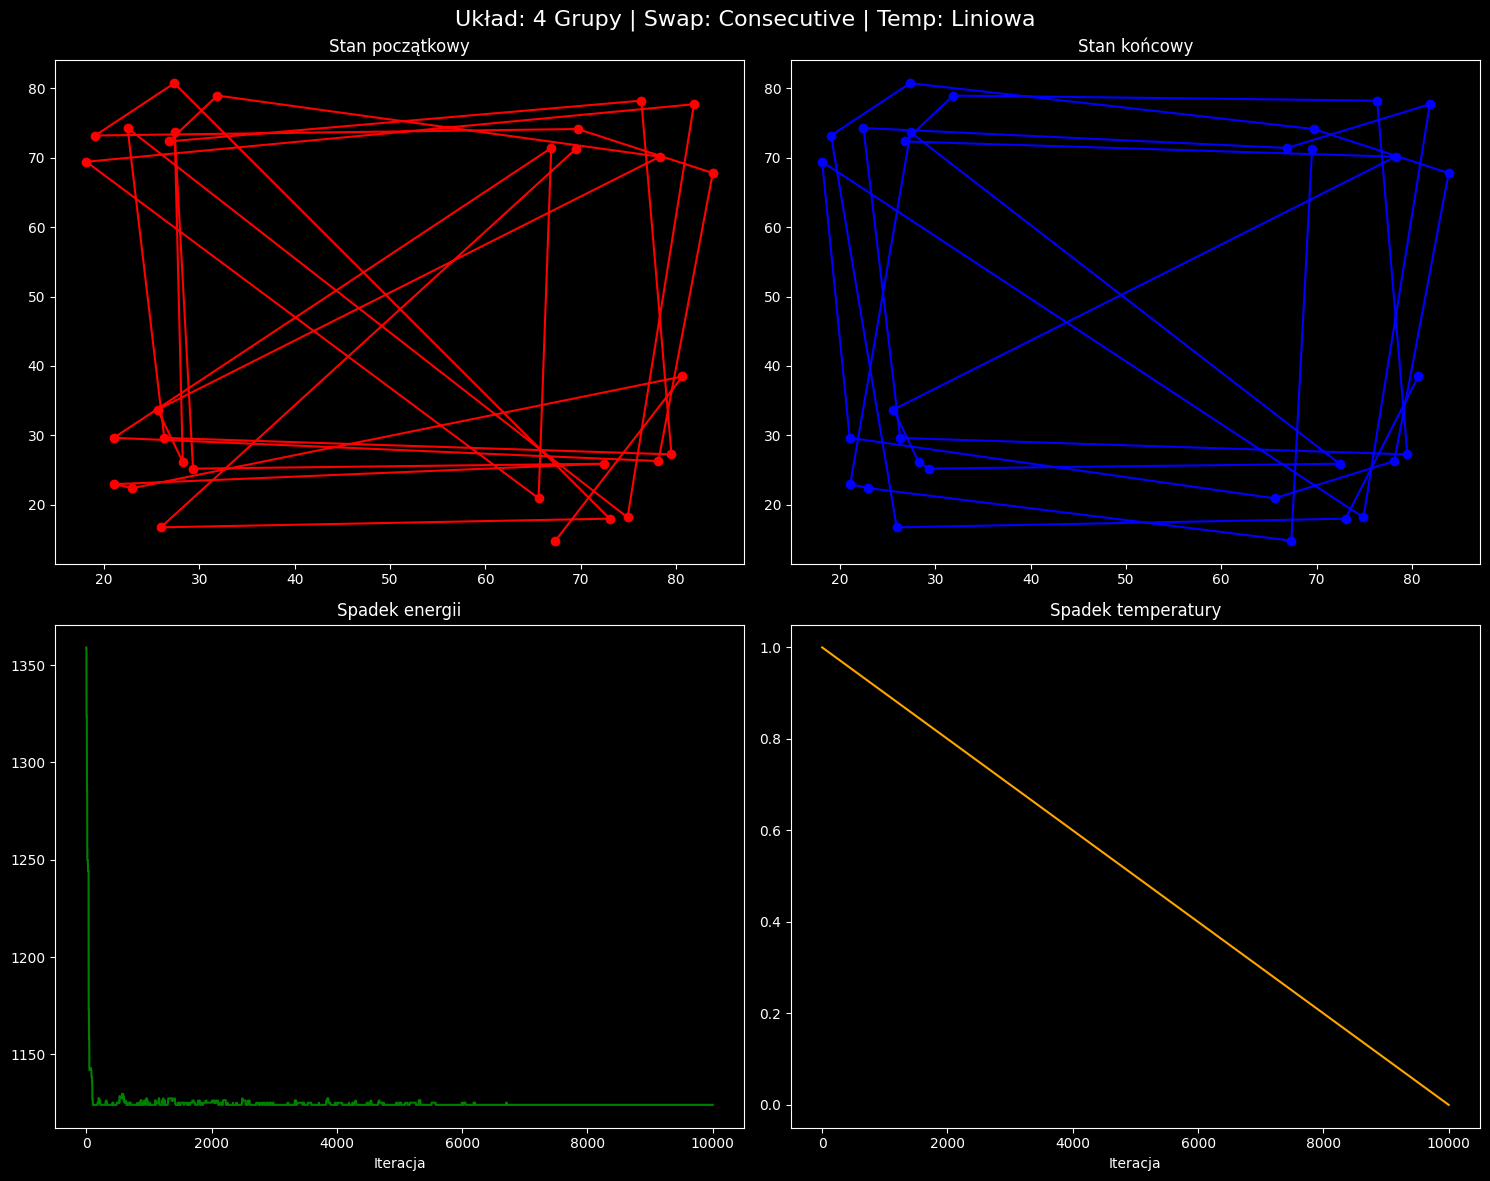

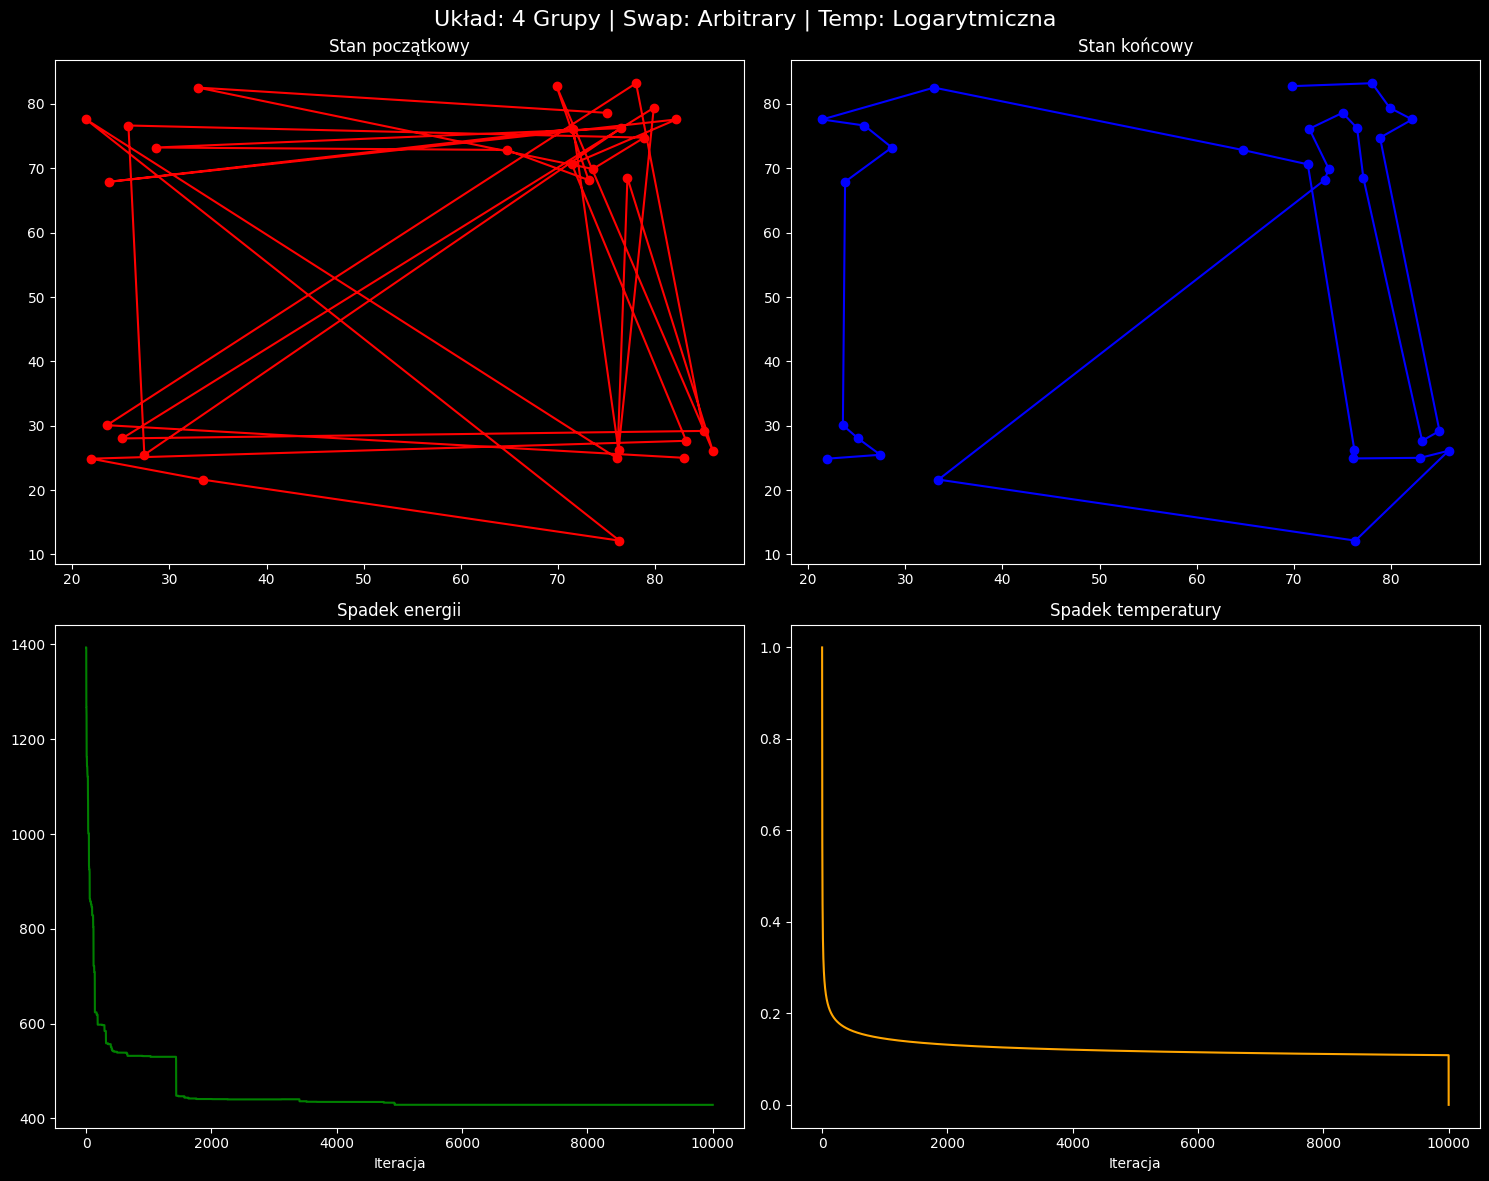

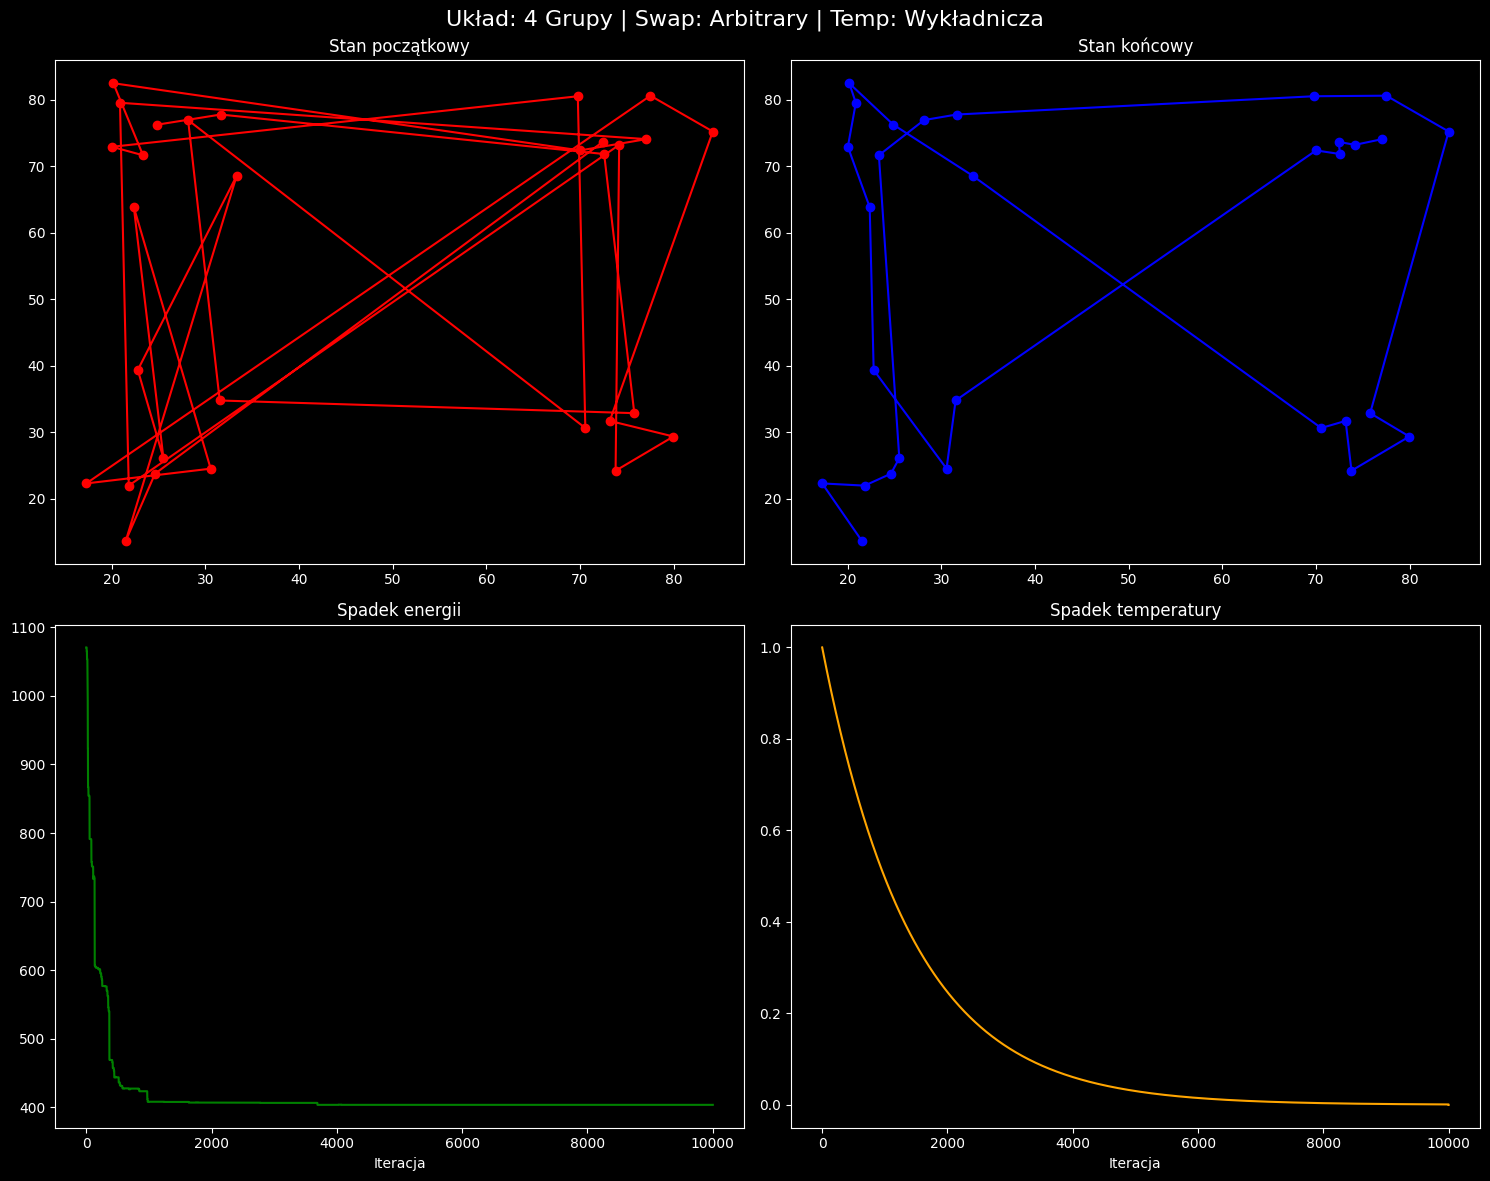

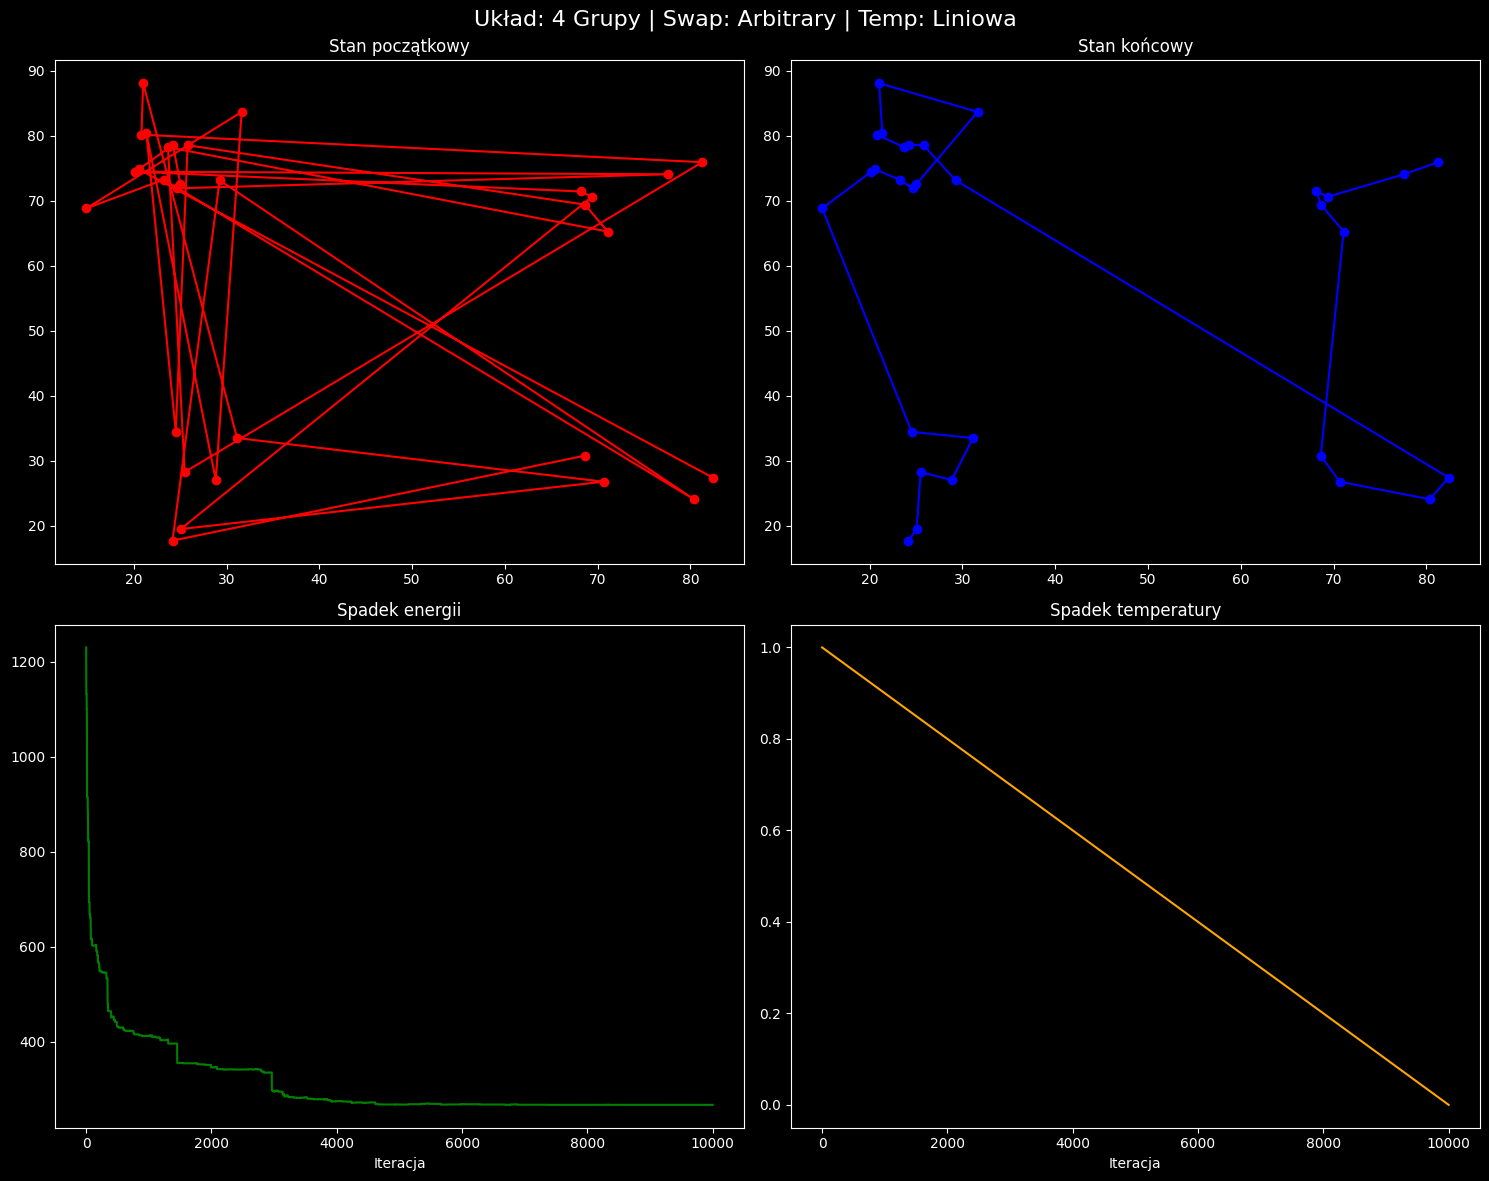

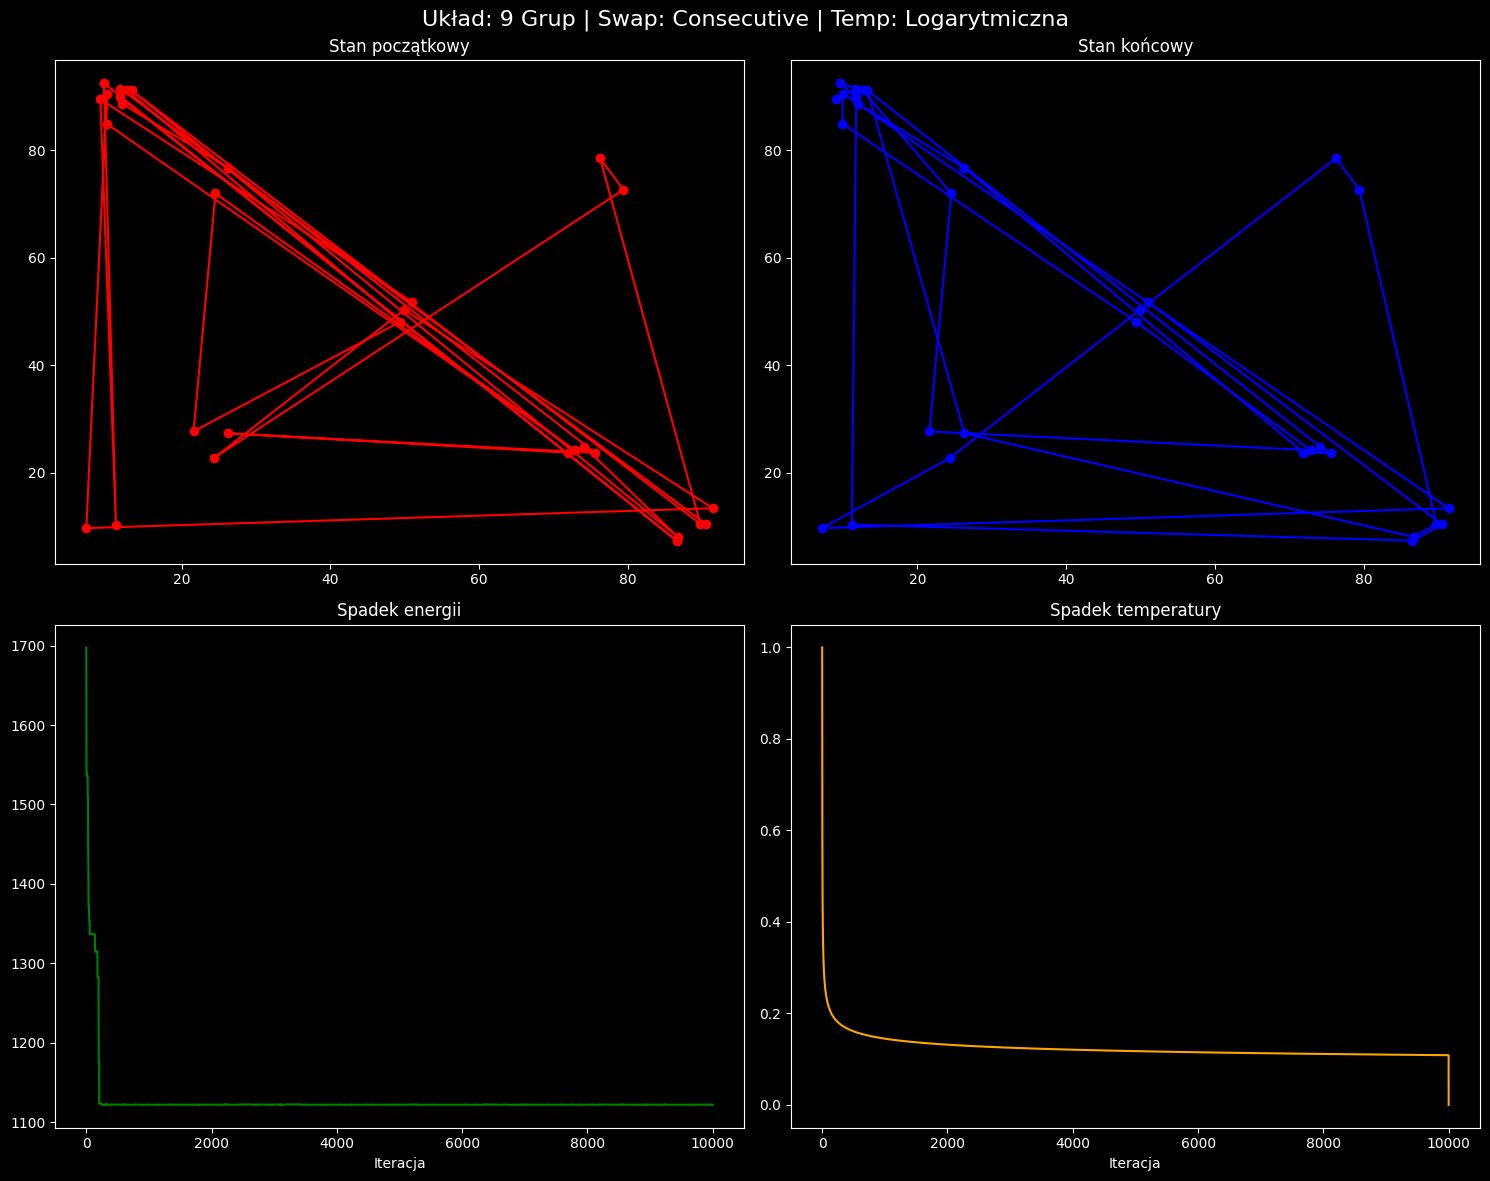

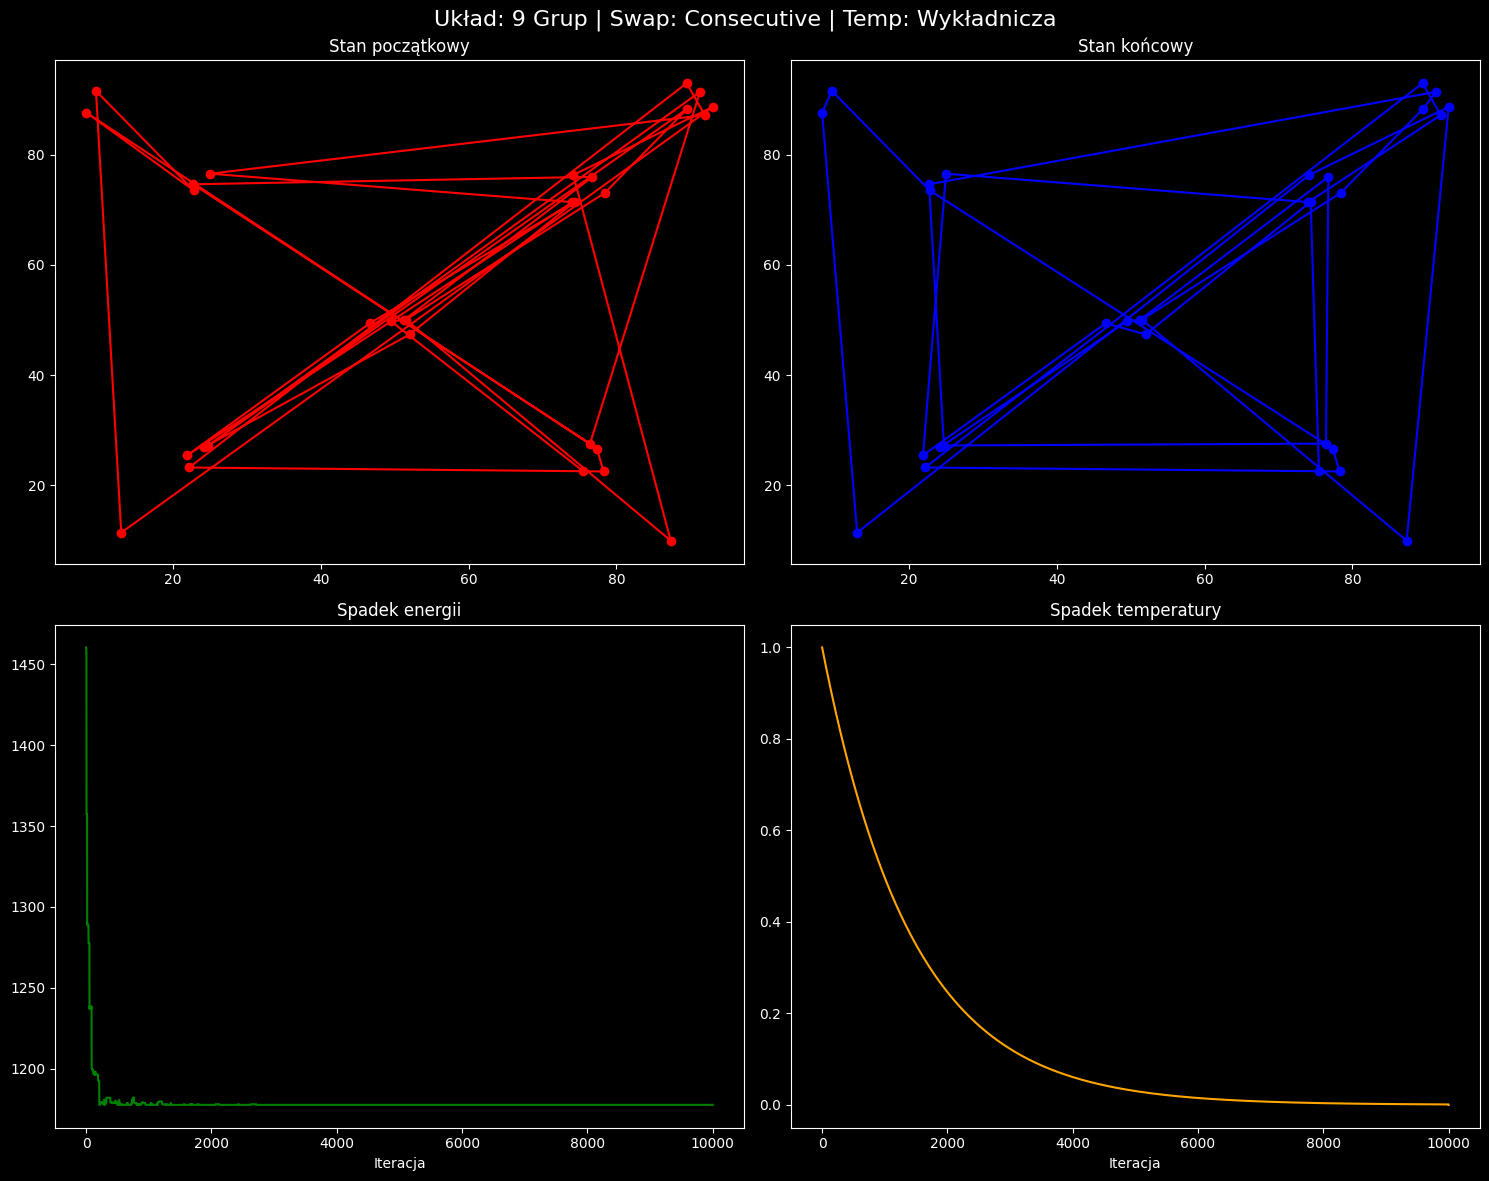

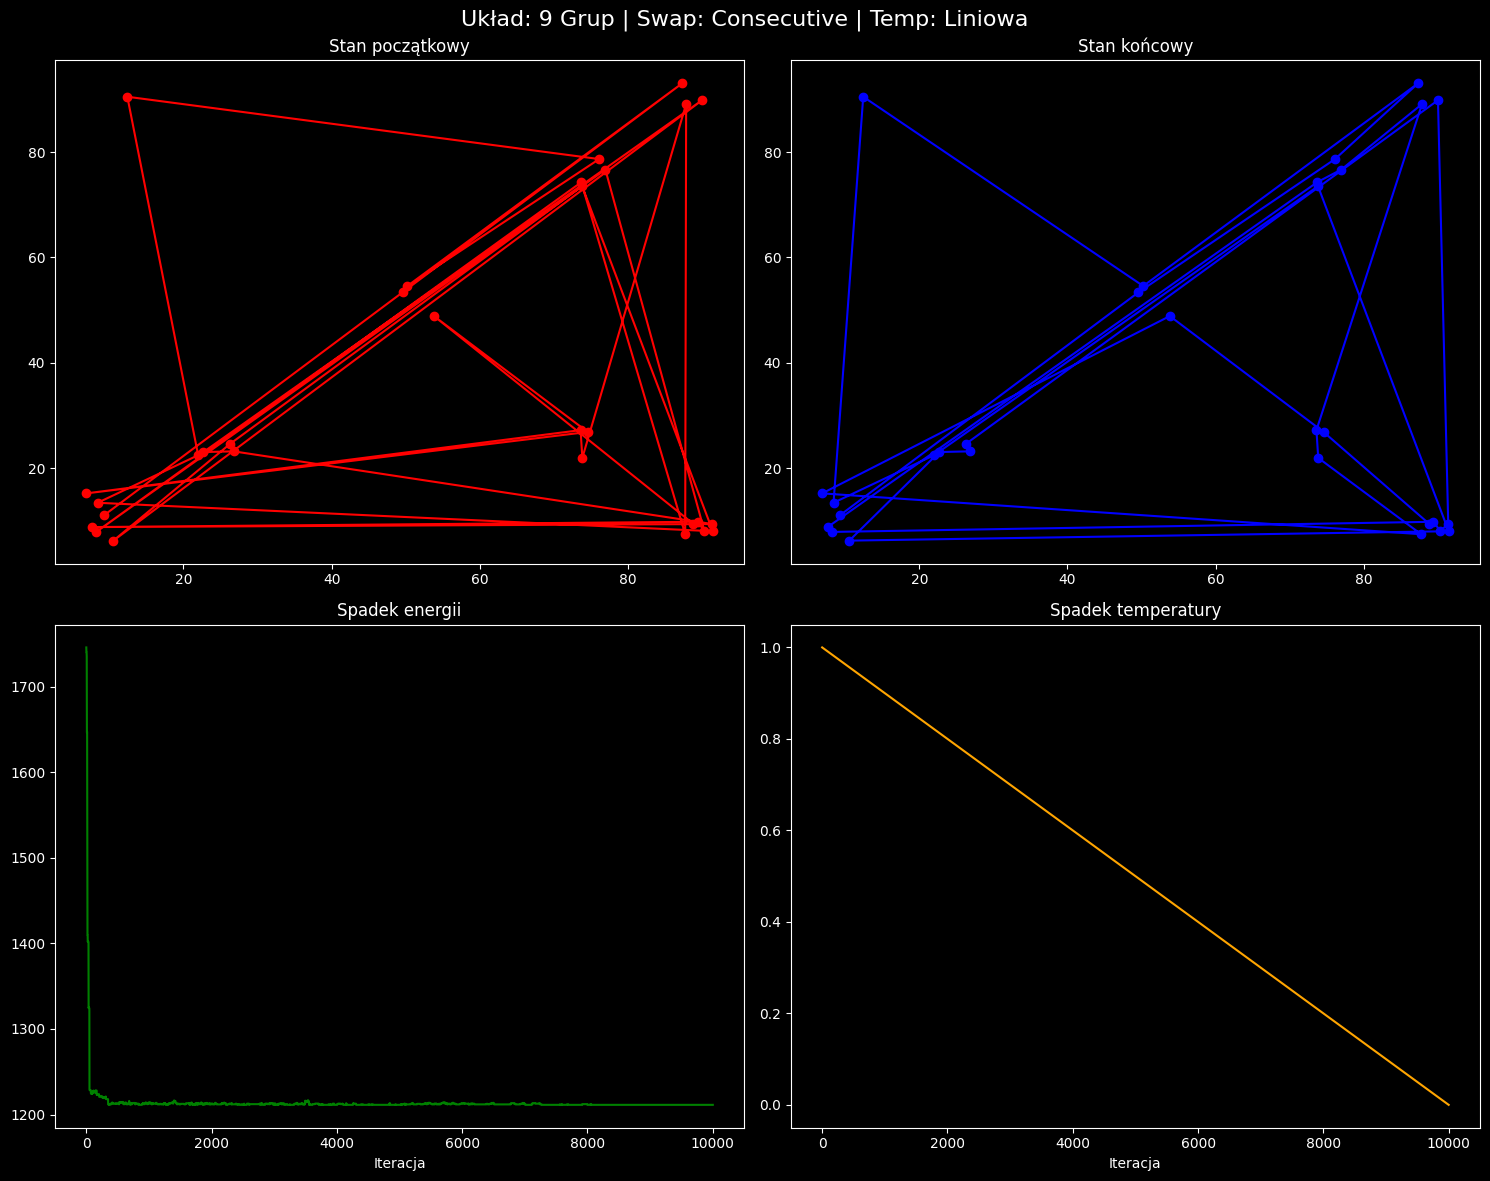

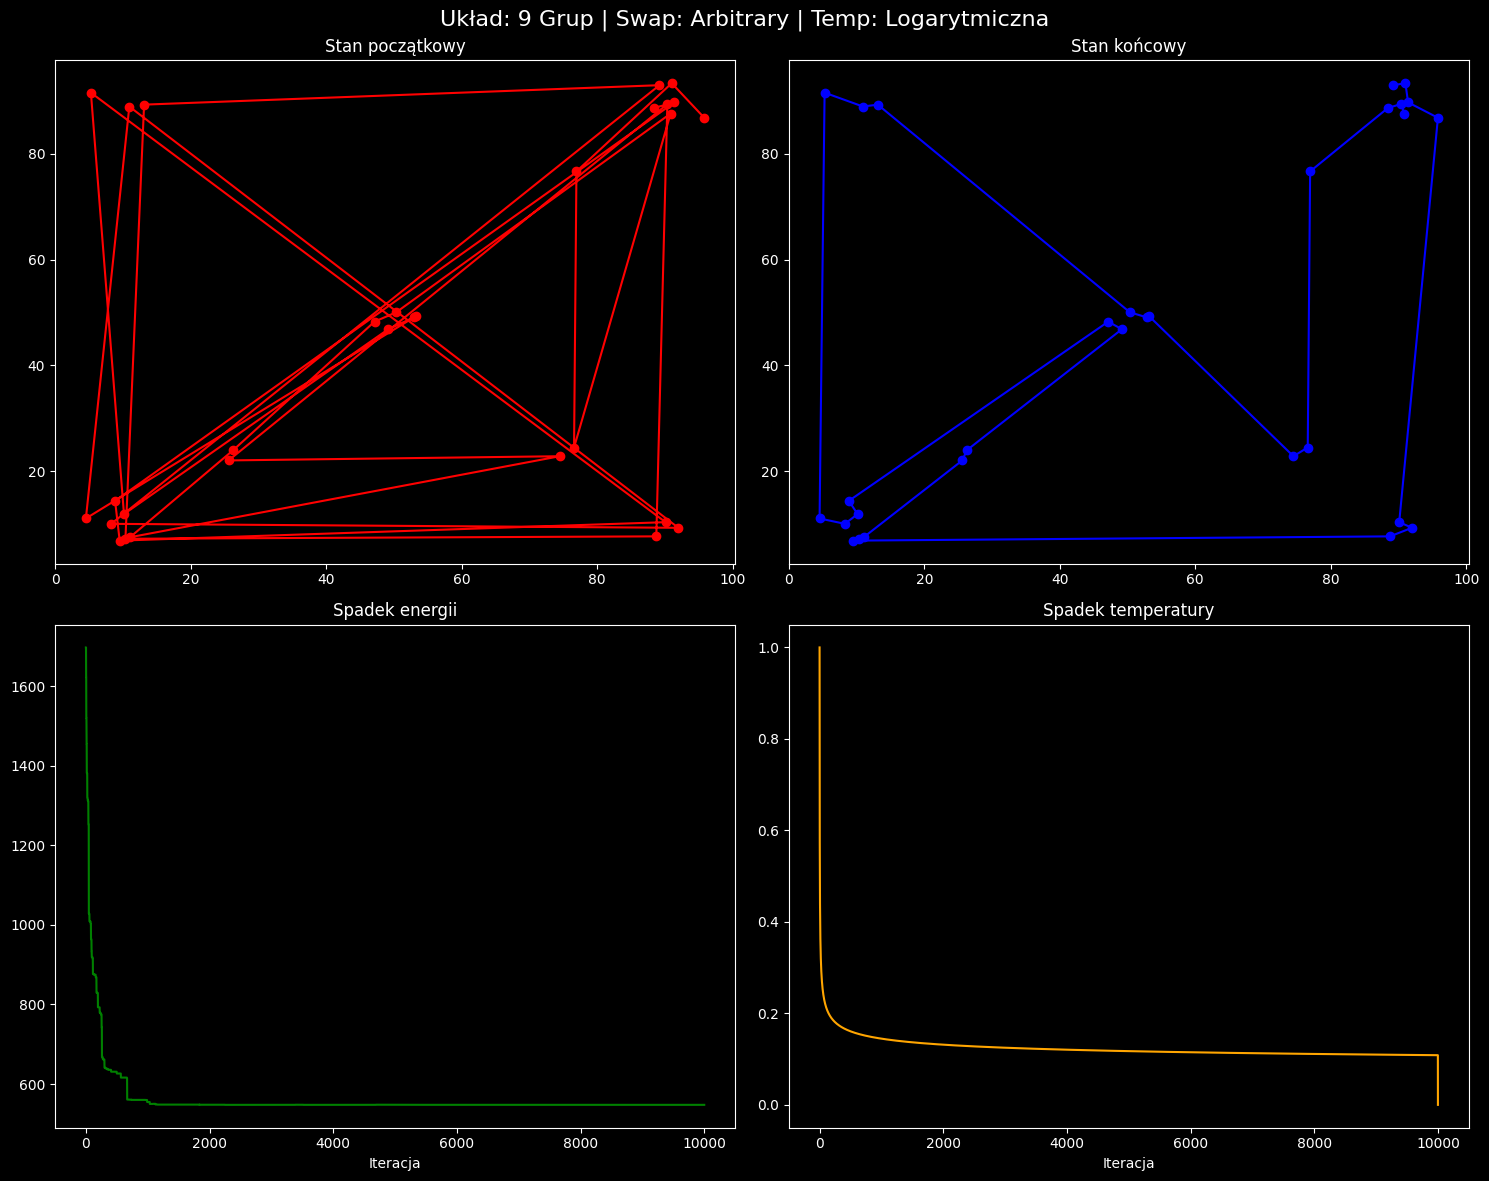

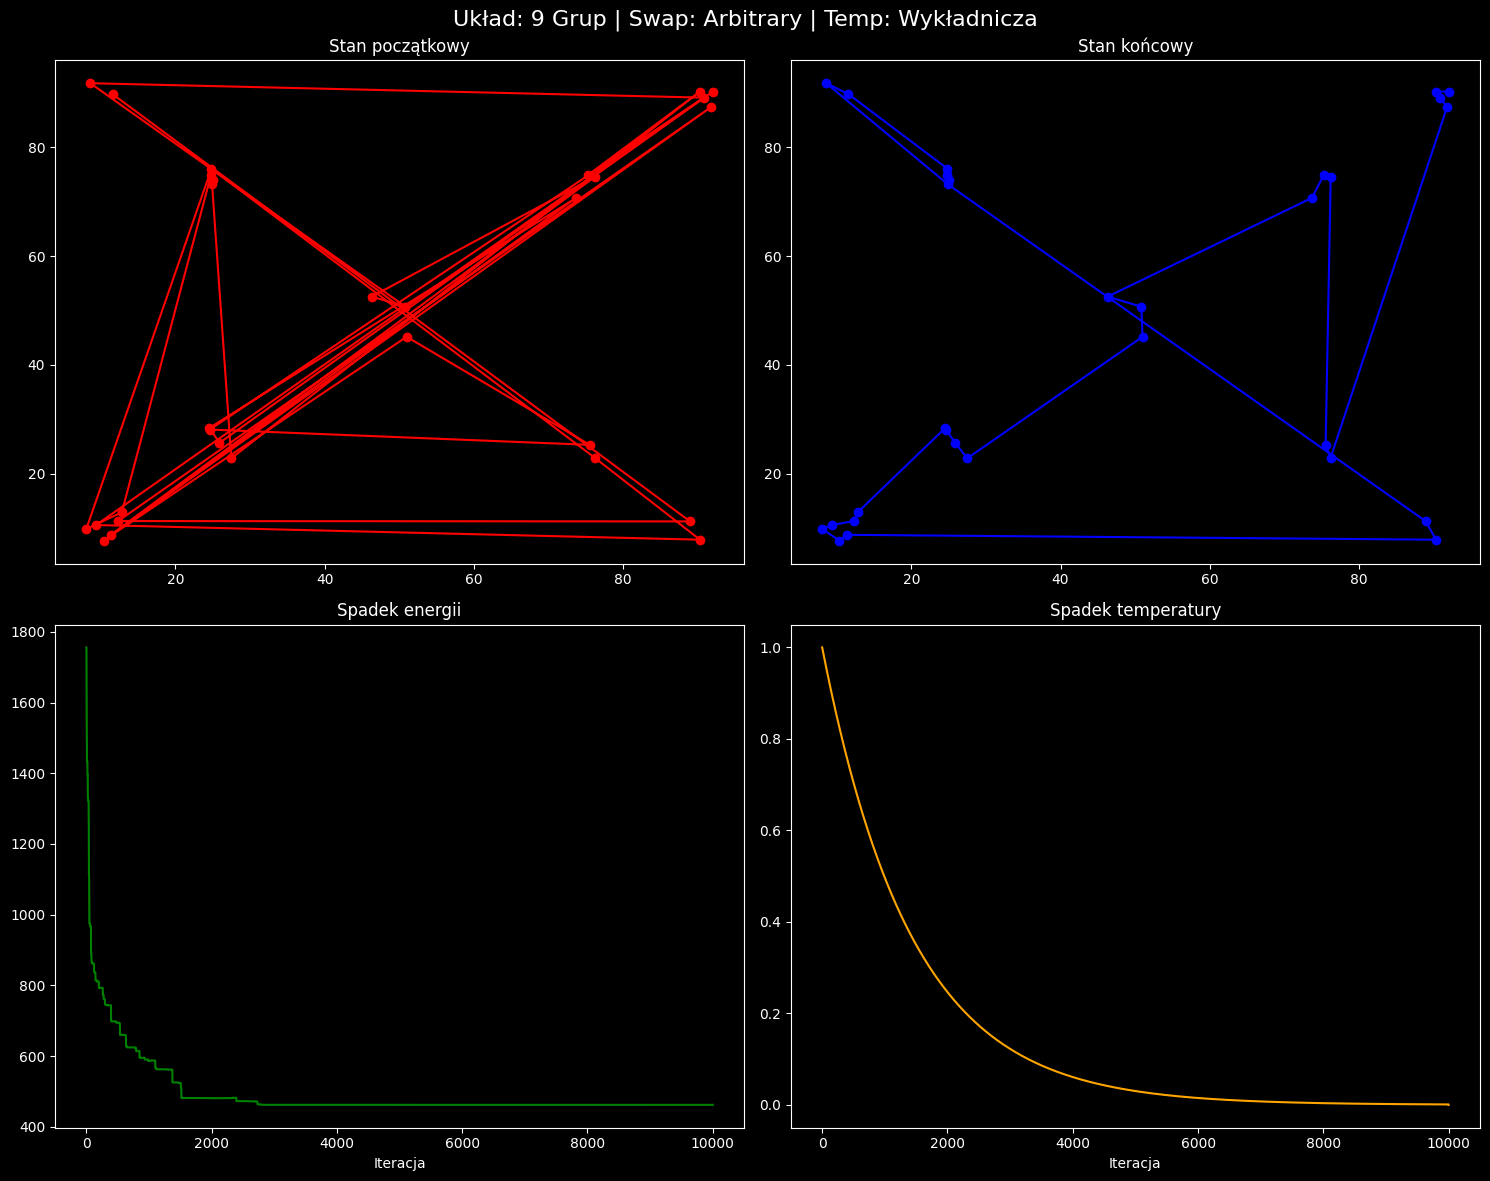

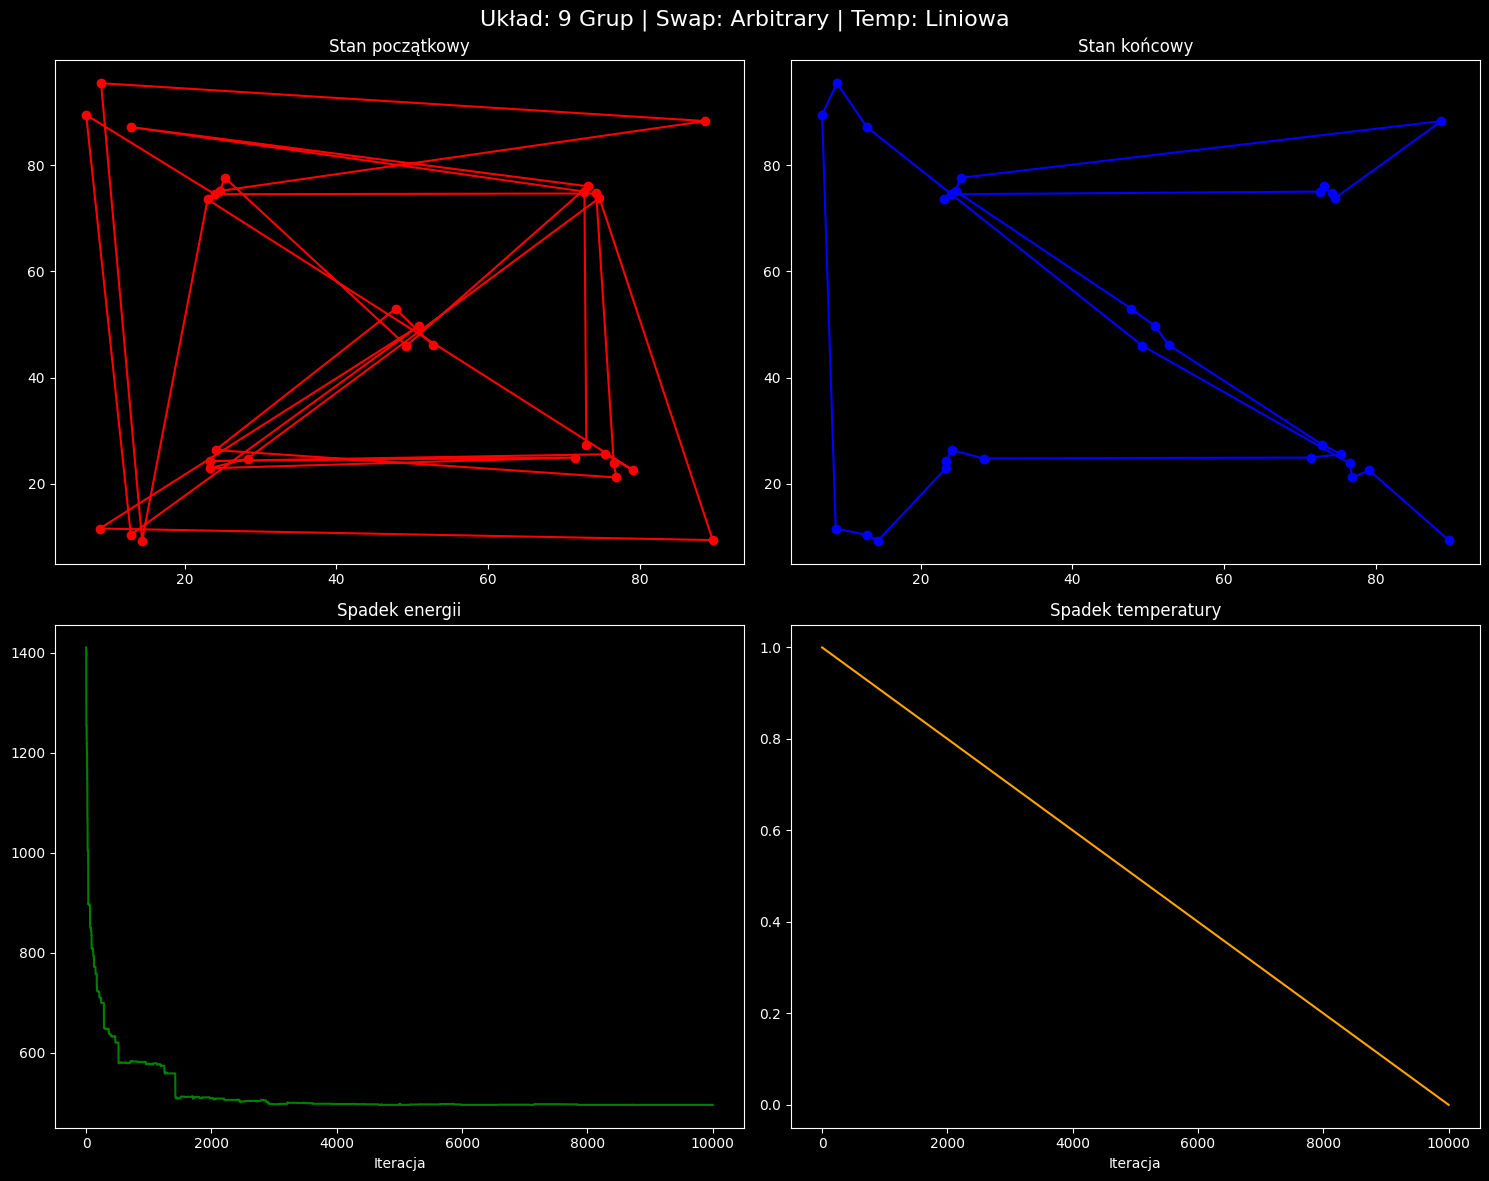

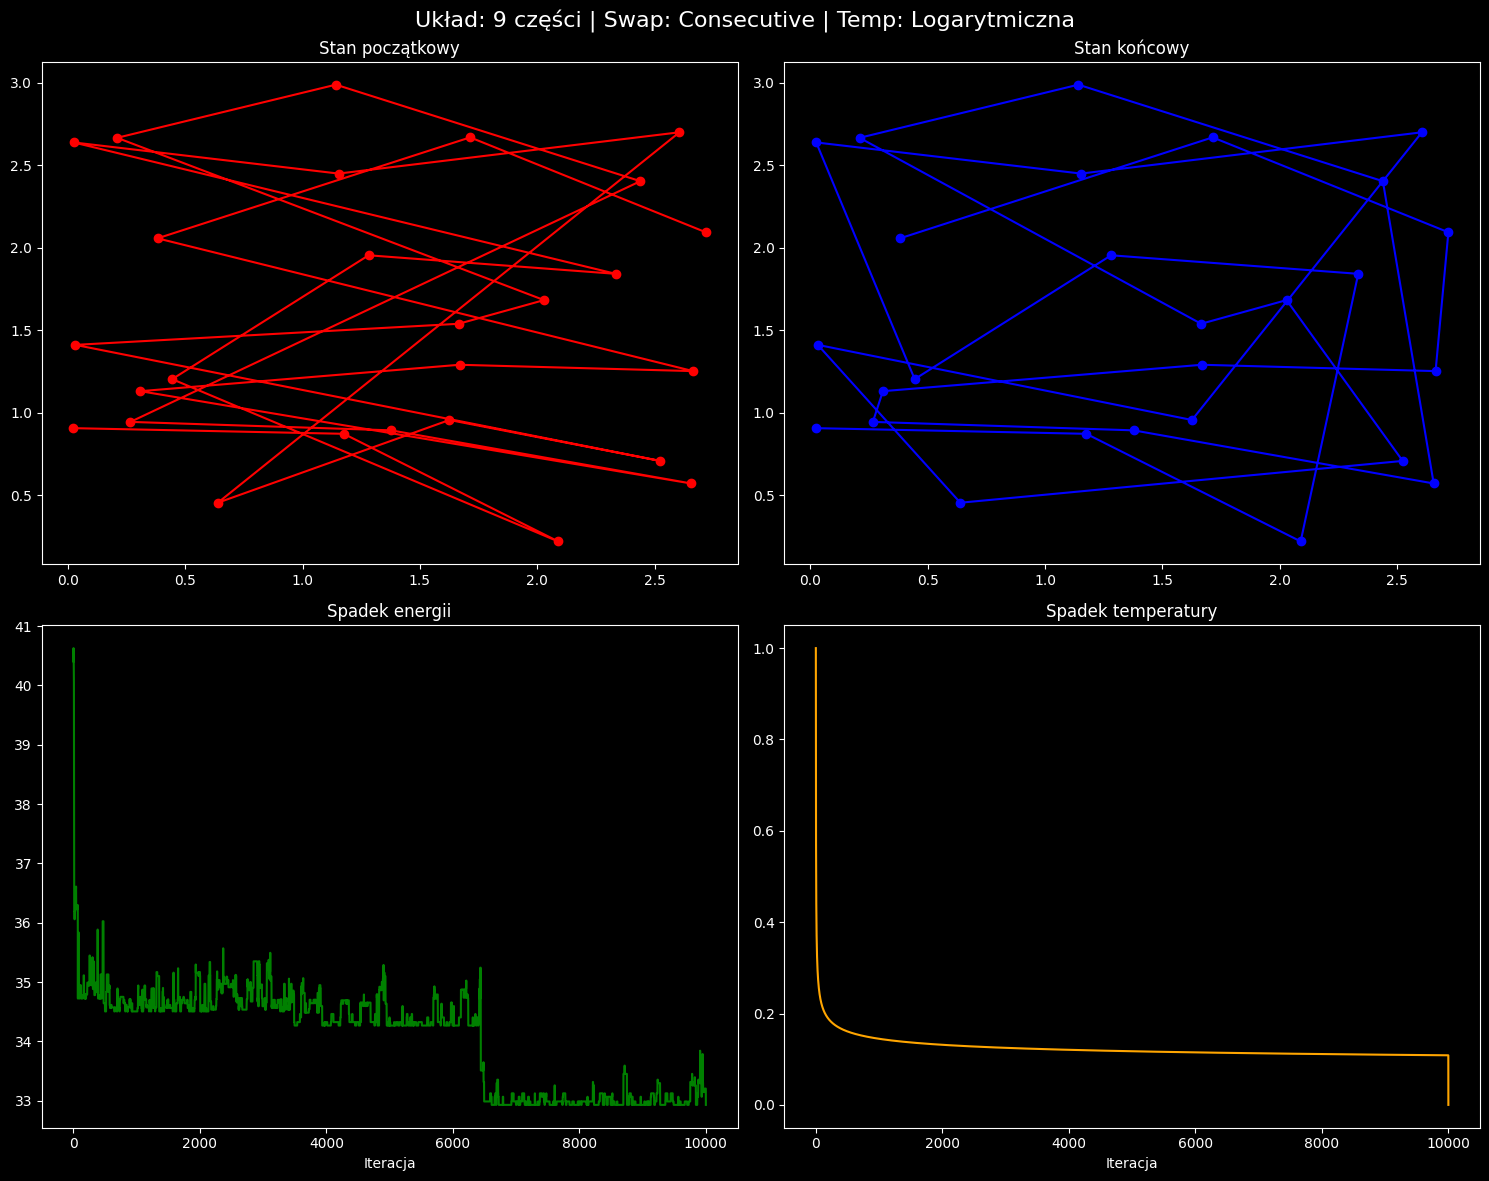

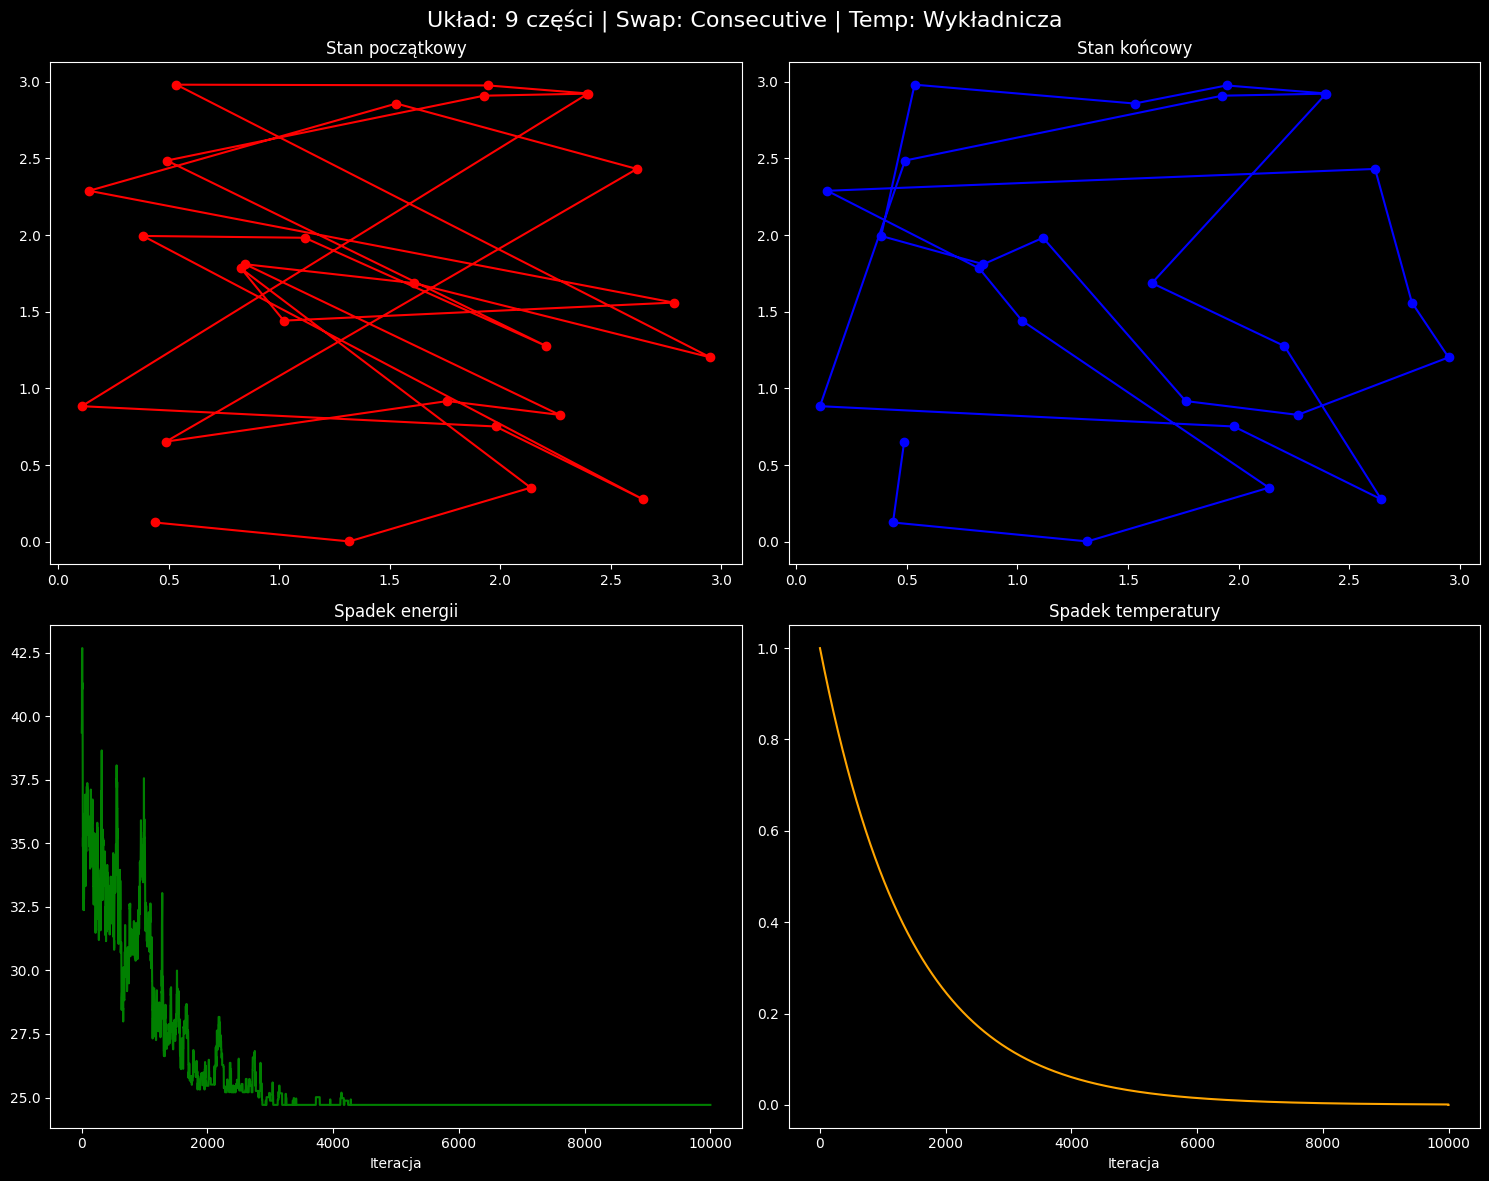

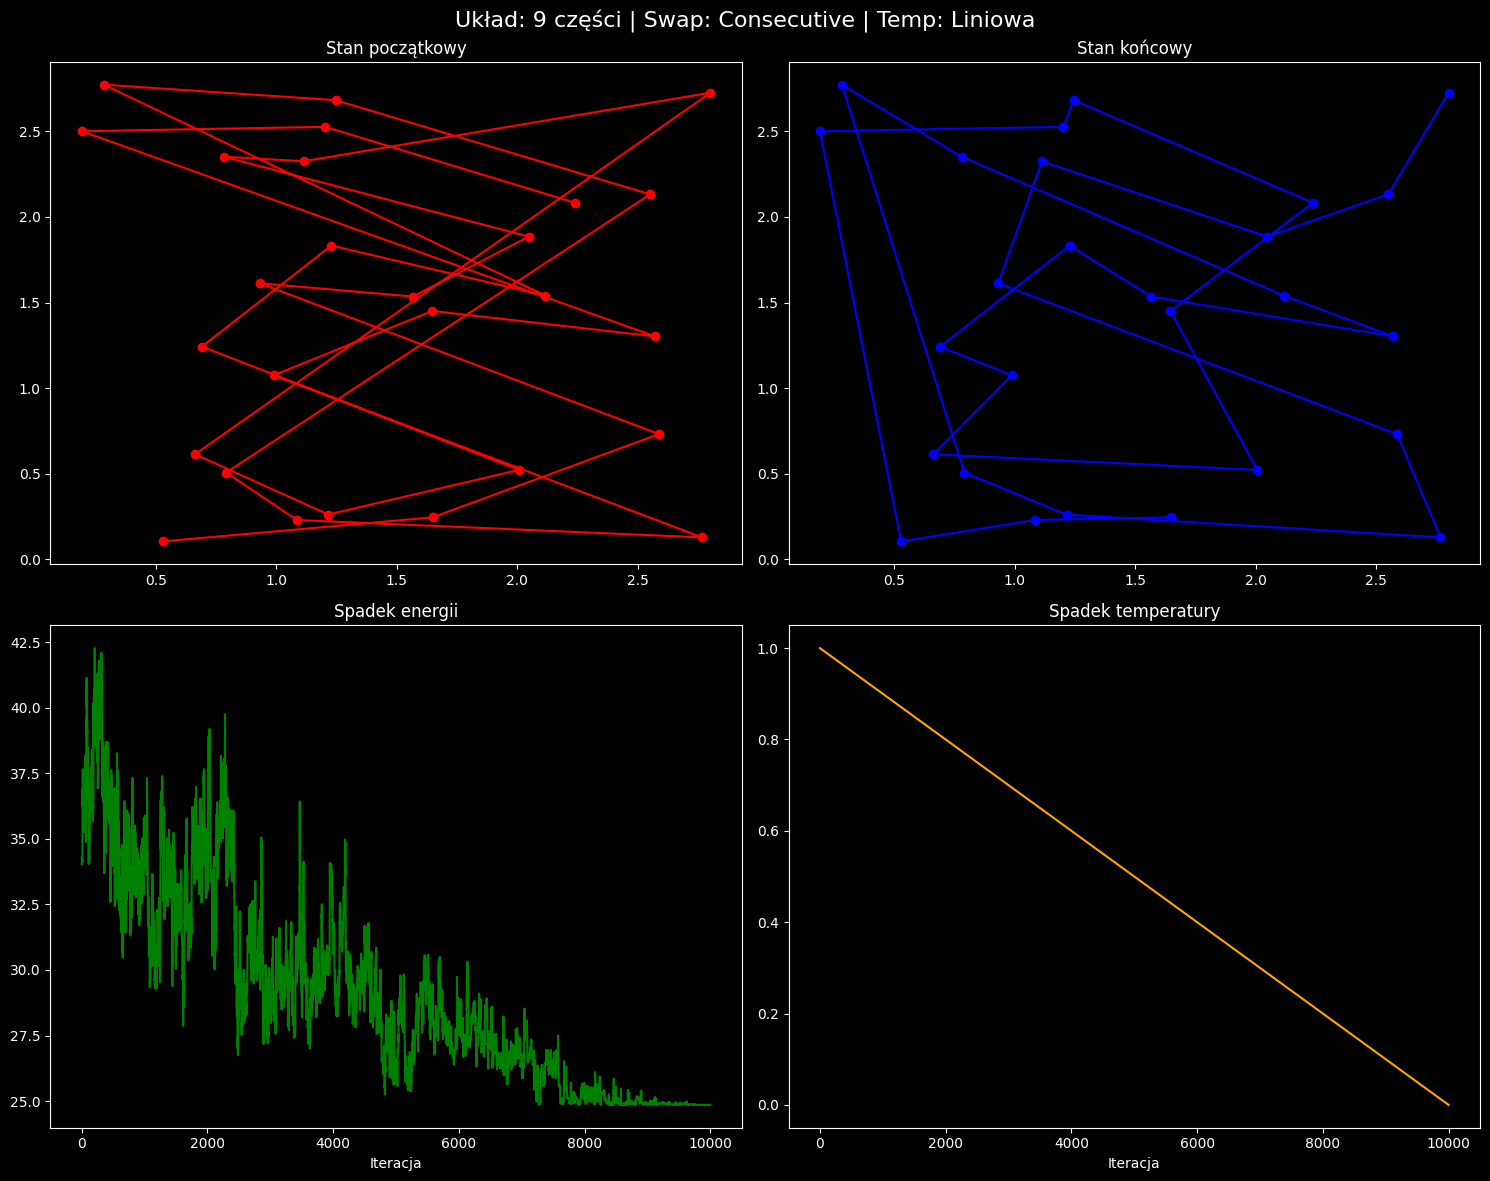

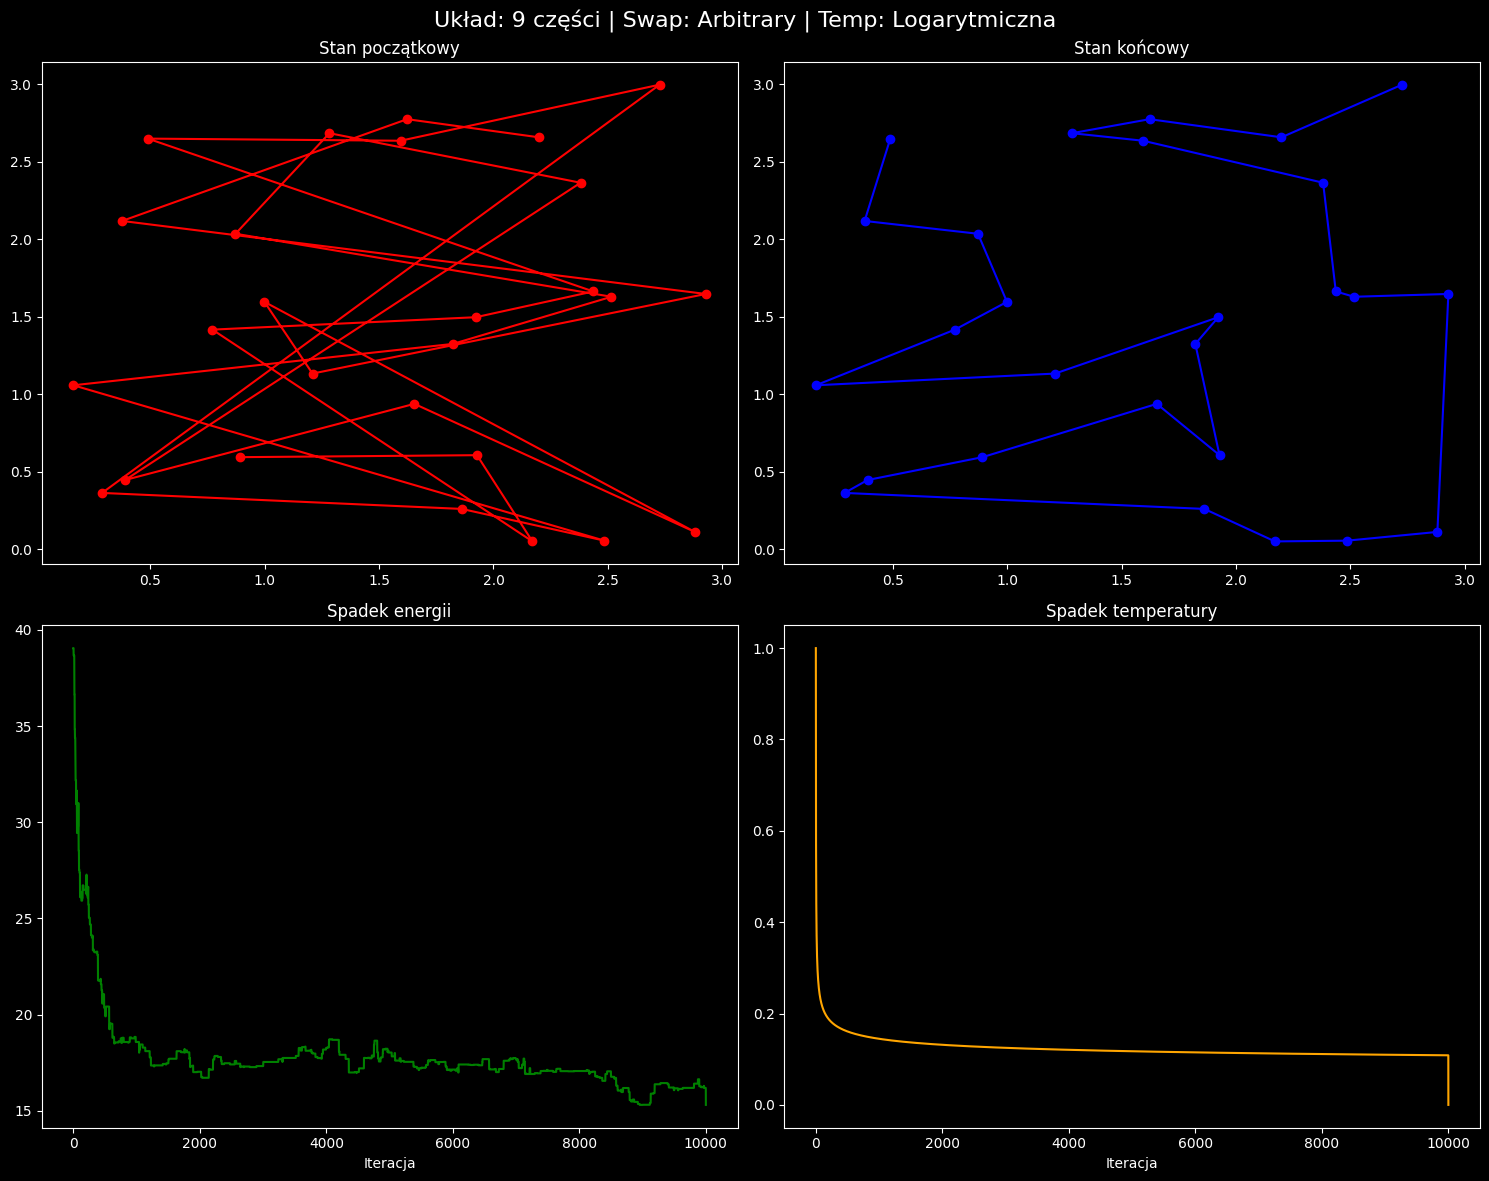

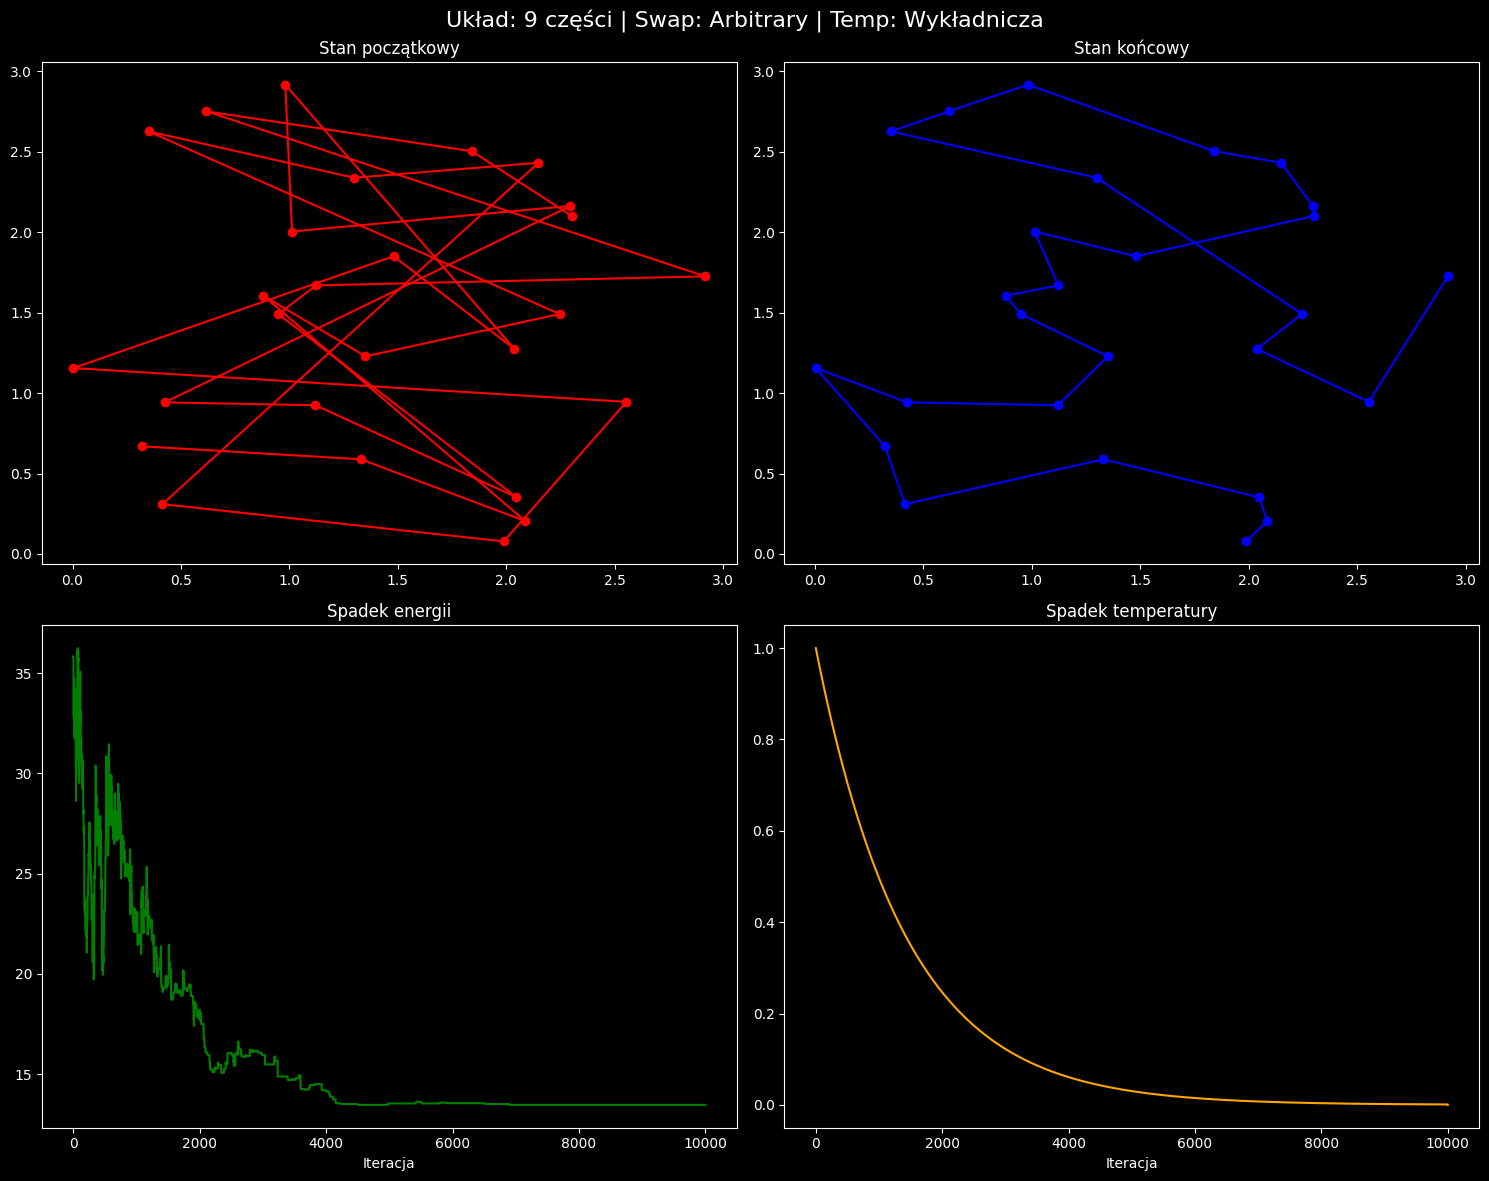

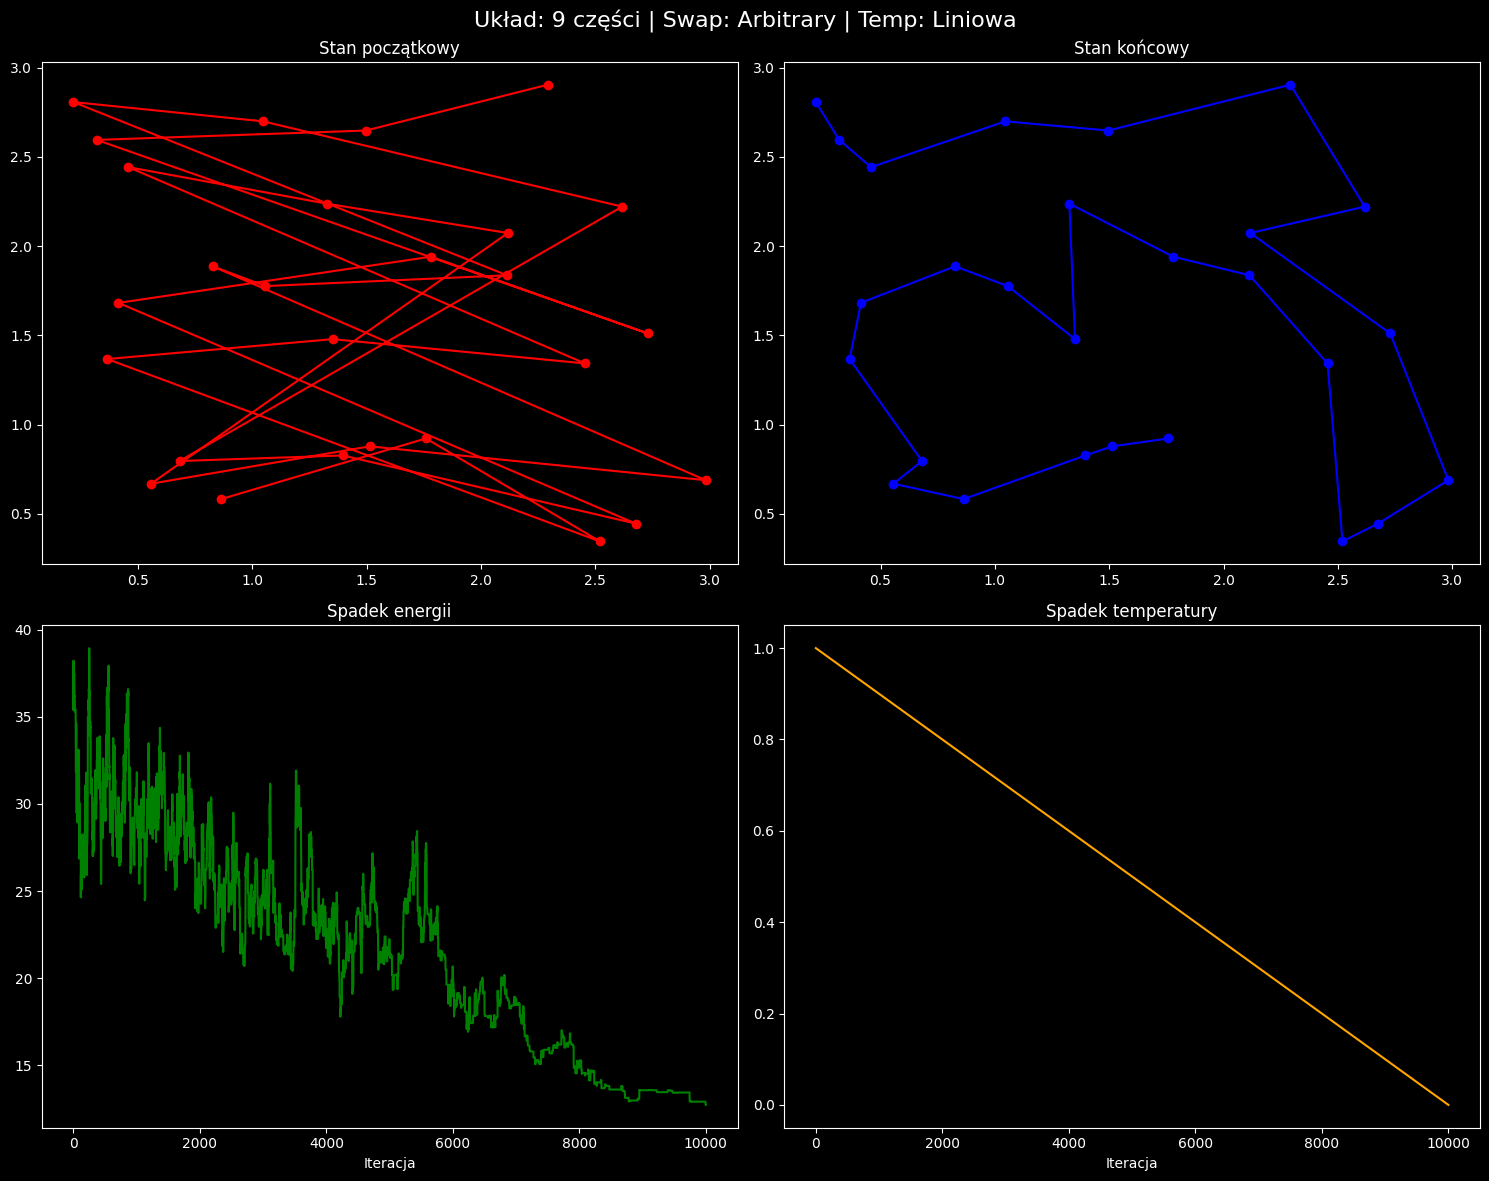

In [24]:
def edges(G):
    n = len(G)
    return [(G[i],G[(i+1)%n]) for i in range(n-1)]


def plot_full_report(G_init, G_final, temps, energies, title):
    fig, axes = plt.subplots(2, 2, figsize=(15, 12))
    fig.suptitle(title, fontsize=16)

    # 1. Stan początkowy (Tylko otwarta ścieżka)
    axes[0, 0].set_title("Stan początkowy")
    axes[0, 0].plot(G_init[:, 0], G_init[:, 1], 'ro-')

    # 2. Stan końcowy (Tylko otwarta ścieżka)
    axes[0, 1].set_title("Stan końcowy")
    axes[0, 1].plot(G_final[:, 0], G_final[:, 1], 'bo-')

    # 3. Wykres energii
    axes[1, 0].set_title("Spadek energii")
    axes[1, 0].plot(energies, color='green')
    axes[1, 0].set_xlabel("Iteracja")

    # 4. Wykres temperatury
    axes[1, 1].set_title("Spadek temperatury")
    axes[1, 1].plot(temps, color='orange')
    axes[1, 1].set_xlabel("Iteracja")

    plt.tight_layout()
    plt.show()

import itertools

layouts = {0: "Jednostajny", 1: "Grid", 2: "Pierścień", 3: "4 Grupy", 4: "9 Grup", 5: "9 części"}
mod_funcs = {"Consecutive": swap_consecutive, "Arbitrary": swap_arbitrary}

n_points = 30
max_iter = 10000

# Parujemy funkcję z jej dedykowanym parametrem chłodzenia dla 10 000 iteracji
temp_configs = {
    "Logarytmiczna": (temp_log, 1.0),       # Skalar dla logarytmu
    "Wykładnicza": (temp_exp, 0.9993),      # (0.9993^10000 daje powolny spadek do ok. 0.001)
    "Liniowa": (temp_lin, 0.0001)           # 1.0 / 10000 iteracji daje dokładnie 0.0001 na krok
}

for (l_key, l_name), (m_name, m_func), (t_name, (t_func, param)) in itertools.product(
    layouts.items(),
    mod_funcs.items(),
    temp_configs.items()
):
    G_initial = generate_vertex(n_points, l_key)

    # Przekazujemy 'param' wydobyty ze słownika zamiast sztywnego 0.95
    G_final, temps, energies = solve(
        G_initial.copy(),
        t_func,
        m_func,
        max_iter,
        cooling_param=param
    )

    title = f"Układ: {l_name} | Swap: {m_name} | Temp: {t_name}"
    plot_full_report(G_initial, np.array(G_final), temps, energies, title)